# Predicción de ingresos de videojuegoscon PySpark

## Yael Charles Marin

## Módulo 6 - Big Data

Este proyecto procesa el dataset completo de [Video Game Market Price and Revenue Dataset](https://www.kaggle.com/datasets/amith1707/video-game-market-price-and-revenue-dataset) con Spark y entrena una regresión de MLlib.

Link a tableu: [Tablero publicado](https://public.tableau.com/views/tableu_proyecto/Videojuegos_mercado_e_ingresos_4_observaciones?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

Link a github: [Github del equipo](https://github.com/EmilioQuinonez/VACAS_IA/tree/main/docs/RETO_DATOS/proyecto_individual)

    // El archivo está en
    docs/RETO_DATOS/proyecto_individual/mod6_proyecto_A01711111

El CSV ocupa **4,983,660,763 bytes (4.98 GB)** y contiene 130 columnas.

**Objetivo:** predecir `estimated_revenue_usd` en la cuarta observación futura del mismo juego, plataforma y tienda. Se reconstruyen `label_usd` y `target_date` con `lead(..., 4)` sobre las series limpias, ordenadas por fecha. Es el ingreso de esa observación, no la suma de ingresos del intervalo.

**Flujo del notebook:** configuración de Colab → descarga → auditoría y limpieza → EDA descriptivo del dataset limpio → construir label a cuatro observaciones → split temporal → EDA de entrenamiento para modelado → ajuste y evaluación → predicciones → CSV para Tableau.




## 1. Preparación inicial, imports y configuración
En esta sección se instalan las dependencias y se reúnen todas las bibliotecas del notebook.

Los imports quedan agrupados por su función y la creación de la sesión de Spark se realiza en la sección 2, después de configurar Java y la memoria de la JVM.

### 1.1. Instalación de dependencias
Ejecutar en Google Colab. Se fija PySpark 4.0.1 para mantener un entorno de ejecución definido.

In [ ]:
%pip install -q "pyspark==4.0.1" "pandas>=2.2,<3" "matplotlib>=3.8,<4" "seaborn>=0.13,<0.14" "requests>=2.31,<3" "psutil>=5.9,<8" tqdm

### 1.2. Bibliotecas del proyecto
Las bibliotecas estándar manejan rutas, descargas y tiempos,  pandas y las herramientas gráficas solo reciben agregados o muestras pequeñas de datos.

PySpark realiza la preparación y el aprendizaje sobre los datos completos elegibles.

In [ ]:
# Bibliotecas estándar: archivos, procesos y medición de tiempos.
import csv
import math
import os
import re
import shutil
import subprocess
import sys
import tempfile
import time
import multiprocessing
from itertools import accumulate
from pathlib import Path
from urllib.parse import quote
# Acceso a las descargas individuales de Google Colab.
try:
    from google.colab import files
except ImportError as exc:
    raise RuntimeError(
        "Este notebook está preparado para Google Colab. Súbelo a Colab y usa una sesión nueva con CPU."
    ) from exc

# Recursos del sistema y descarga del dataset.
import psutil
import requests
from tqdm.auto import tqdm

# Análisis, gráficas y presentación de resultados.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from matplotlib.ticker import StrMethodFormatter
from IPython.display import Markdown, display

# Procesamiento distribuido y ventanas temporales.
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

# Pipeline, preparación de características, regresión y evaluación de MLlib.
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (
    Imputer,
    OneHotEncoder,
    SQLTransformer,
    StringIndexer,
    VectorAssembler,
)
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder

### 1.3. Parámetros que pueden modificarse
Cambiar las tres proporciones y volver a ejecutar el flujo permite comparar otras divisiones. Las fechas de corte aproximan esas proporciones por cantidad de registros y cada fecha permanece completa en una partición. Las exclusiones por horizonte temporal modifican las proporciones finales. Esta versión fija el objetivo en cuatro observaciones futuras; su duración en días depende de cada serie.

In [ ]:
# División del dataset
TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10
SEED = 42

# Numero de observaciones para graficas y calcular ventana
HORIZON_OBSERVATIONS = 4
MAX_PLOT_ROWS = 20_000
MAX_TABLEAU_ROWS = 20_000

# Grid de hiperparametros
REG_PARAMS = [0.01, 0.1]
ELASTIC_NET_PARAMS = [0.0, 0.5]
MAX_ITER = 30

# Variables del dataset
DATASET_REF = "amith1707/video-game-market-price-and-revenue-dataset"
DATASET_VERSION = 1
KAGGLE_FILE = "data/full/videogames_full.csv/videogames_processed.csv"
EXPECTED_BYTES = 4_983_660_763

ratios = (TRAIN_RATIO, VAL_RATIO, TEST_RATIO)

## 2. Preparación del ambiente de Colab
Se comprueba Java y se configura la memoria antes de iniciar la JVM. Spark se ejecuta sobre CPU dentro de la máquina de Colab, con los hilos de trabajo disponibles.

In [ ]:
# Comprobar Java 17 o superior y configurar las rutas antes de iniciar Spark.
java = shutil.which("java")
java_version = subprocess.run([java, "-version"], capture_output=True, text=True) if java else None
version_match = re.search(r'version "(\d+)', (java_version.stderr + java_version.stdout) if java_version else "")

if not version_match or int(version_match.group(1)) < 17:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "openjdk-17-jre-headless"], check=True)
    java = str(next(Path("/usr/lib/jvm").glob("java-17-openjdk-*/bin/java")))

os.environ["JAVA_HOME"] = str(Path(java).resolve().parents[1])
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

In [ ]:
print(subprocess.check_output([str(Path(os.environ["JAVA_HOME"]) / "bin/java"), "-version"], stderr=subprocess.STDOUT, text=True))

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



**Comprobación del ambiente.**

La celda anterior muestra la versión de Java disponible, se requiere Java 17 o superior, lo que se cumple ya que muestra la versión de jdk 21.

In [ ]:
# Rutas de datos, modelo y archivos para Tableau.
ROOT = Path("/content/videogames")
DATA_DIR = ROOT / "data"
PARQUET_DIR = ROOT / "parquet"
MODEL_DIR = ROOT / "model_4obs"
TABLEAU_DIR = Path("/content/tableau")

for directory in (DATA_DIR, PARQUET_DIR, ROOT / "spark_tmp", TABLEAU_DIR):
    directory.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "videogames_processed.csv"

# Configurar la memoria antes de que getOrCreate() inicie la JVM.
ram = psutil.virtual_memory()
free_gib = shutil.disk_usage("/content").free / 2**30
if free_gib < 20:
    raise RuntimeError("Se requieren al menos 20 GiB de disco libre para el CSV, Parquet y temporales.")
DRIVER_GB = max(1, min(4, int(ram.available / 2**30 * 0.45)))

# Iniciar Spark.
spark = (SparkSession.builder.master("local[*]")
    .appName("VideoGames_Revenue_4_Observations")
    .config("spark.driver.memory", f"{DRIVER_GB}g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.local.dir", str(ROOT / "spark_tmp"))
    .getOrCreate())

spark.sparkContext.setLogLevel("WARN")

sns.set_theme(style="whitegrid", palette=["#007F86", "#E07A3F", "#14213D"])
plt.rcParams.update({"figure.figsize": (11, 4), "axes.titlesize": 13})

In [ ]:
cores = multiprocessing.cpu_count()  # Núcleos físicos/lógicos totales disponibles en el entorno local
print(f"RAM total: {ram.total / 2**30:.1f} GiB; disponible: {ram.available / 2**30:.1f} GiB")
print(f"Disco libre: {free_gib:.1f} GiB; JVM: {DRIVER_GB} GiB; núcleos asignables en local[*]: {cores}")
print("Python:", sys.version.split()[0], "| Spark:", spark.version, "| Master:", spark.sparkContext.master)

RAM total: 12.7 GiB; disponible: 10.7 GiB
Disco libre: 101.3 GiB; JVM: 4 GiB; núcleos asignables en local[*]: 2
Python: 3.13.18 | Spark: 4.0.1 | Master: local[*]


**Lectura de los recursos.**

Las cifras impresas corresponden al momento de esta ejecución, se obtuvo un total de 12.7 gib de ram, con 9.9 disponible, un disco libre de 101.3 gib, la maquina virtual de java con 4 gib y 2 nucleos de cpu.

Además de las versiones de python y spark compatibles entre si.

## 3. Descarga del archivo completo
Se descarga solo el archivo completo del dataset mediante el endpoint público de Kaggle, no se descargan directamente los archivos `train/val/test` del autor ni los subconjuntos.

La transferencia se escribe por bloques en un archivo `.part`, si se interrumpe, se intenta reanudar. El archivo se acepta únicamente si su tamaño coincide con los metadatos verificados.

Si Kaggle devuelve una página HTML o limita el acceso, se sugiere descargar manualmente `videogames_processed.csv`, colocarlo en `CSV_PATH` y volver a ejecutar la celda.

In [ ]:
# Definir una descarga por bloques que puede reutilizar o reanudar el archivo.
DOWNLOAD_URL = (f"https://www.kaggle.com/api/v1/datasets/download/{DATASET_REF}/"
                f"{quote(KAGGLE_FILE, safe='')}?datasetVersionNumber={DATASET_VERSION}")

def download_csv():
    # Caso 1: el csv ya existe
    if CSV_PATH.exists() and CSV_PATH.stat().st_size == EXPECTED_BYTES:
        print("Se reutiliza el CSV completo ya descargado.")
        return

    # Caso 2: existe una descarga parcial completa
    partial = CSV_PATH.with_suffix(".csv.part")
    if partial.exists() and partial.stat().st_size == EXPECTED_BYTES:
        partial.replace(CSV_PATH)
        return
    for attempt in range(1, 4):
        offset = partial.stat().st_size if partial.exists() else 0
        headers = {"Accept-Encoding": "identity"}

        if offset:
            headers["Range"] = f"bytes={offset}-"
        try:
            with requests.get(DOWNLOAD_URL, headers=headers, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                if "text/html" in response.headers.get("Content-Type", "").lower():
                    raise RuntimeError("Kaggle devolvió HTML. Usa la descarga manual descrita arriba.")
                if response.status_code == 206:
                    content_range = response.headers.get("Content-Range", "")
                    match = re.fullmatch(r"bytes (\d+)-(\d+)/(\d+)", content_range)
                    if not match or int(match[1]) != offset or int(match[3]) != EXPECTED_BYTES:
                        raise RuntimeError(f"Rango inesperado en la descarga: {content_range}")
                elif response.status_code == 200:
                    offset = 0  # Si no admite reanudación, se vuelve a escribir desde el inicio.
                else:
                    raise RuntimeError(f"Estado HTTP inesperado: {response.status_code}")
                with partial.open("ab" if offset else "wb") as handle, tqdm(
                    total=EXPECTED_BYTES, initial=offset, unit="B", unit_scale=True,
                    desc=f"CSV completo · intento {attempt}") as progress:
                    for chunk in response.iter_content(chunk_size=4 * 2**20):
                        if chunk:
                            handle.write(chunk)
                            progress.update(len(chunk))
            if partial.stat().st_size == EXPECTED_BYTES:
                partial.replace(CSV_PATH)
                return
            print("La transferencia quedó incompleta; se intentará reanudar.")
        except requests.RequestException as exc:
            print(f"Intento {attempt}: {type(exc).__name__}. Se conserva el avance.")
    raise RuntimeError("No se completó la descarga. Reejecuta la celda o coloca manualmente el CSV en CSV_PATH.")

In [ ]:
# Descargar el archivo y comprobar su tamaño antes de leerlo con Spark.
download_csv()
size_bytes = CSV_PATH.stat().st_size
if size_bytes != EXPECTED_BYTES or size_bytes < 1_000_000_000:
    raise RuntimeError("El archivo no tiene el tamaño esperado o no cumple el mínimo de 1 GB.")

Se reutiliza el CSV completo ya descargado.


In [ ]:
print(f"Evidencia de volumen: {size_bytes:,} bytes = {size_bytes / 10**9:.2f} GB = {size_bytes / 2**30:.2f} GiB")

Evidencia de volumen: 4,983,660,763 bytes = 4.98 GB = 4.64 GiB


**Comprobación de la descarga.**

Se comprobó que el tamaño coincida con los 4,983,660,763 bytes esperados del archivo del dataset y además supera 1 GB solicitado.

## 4. Lectura y auditoría

El esquema inicial declara las 130 columnas como texto, esto evita una pasada de inferencia y permite contar valores que no se pueden convertir. Luego se convierten explícitamente solo las columnas necesarias a fechas y números.

El lector se detiene ante CSV mal formado en lugar de omitir registros silenciosamente.

Se usan señales de precio, actividad, reputación y características del juego. No se usan otras labels de `target_*`, identificadores como predictores, acumulados, máximos históricos ni variables derivadas cuya disponibilidad temporal no está comprobada.

In [ ]:
# Leer el archivo como texto y definir las columnas que se utilizarán.
# Encabezado esperado, organizado en varias líneas para leerlo.
EXPECTED_HEADER = (
    'game_id,platform,platform_code,storefront,obs_date,days_since_release,current_price_usd,'
    'original_price_usd,discount_pct,is_on_sale,sale_event_name,lowest_price_usd,'
    'decay_factor,price_vs_launch,concurrent_players,peak_ccu_alltime,review_count,'
    'positive_reviews,negative_reviews,steam_rating_pct,user_score,metacritic_score,'
    'wishlist_count,twitch_viewers_proxy,youtube_views_proxy,reddit_mentions,'
    'social_hype_index,has_controversy,controversy_day,estimated_units_sold,'
    'estimated_revenue_usd,revenue_per_review,revenue_per_player,price_na,price_eu,price_gb,'
    'price_jp,price_br,price_au,game_name,developer,publisher,publisher_tier,franchise,genre,'
    'genre_code,subgenre,tags,age_rating,release_date,release_year,release_month,'
    'release_quarter,base_price_usd,dlc_count,expansion_count,achievement_count,'
    'supported_languages,is_free_to_play,is_indie,is_early_access,is_multiplayer,is_online,'
    'is_franchise,is_sequel,is_remaster,is_remake,is_crossplay,has_crossbuy,'
    'publisher_market_share,publisher_avg_budget,subscription_service,discount_intensity,'
    'affordability_index,launch_price_decay,price_change_abs,price_change_pct,price_7obs_avg,'
    'price_30obs_avg,price_volatility,price_all_time_low,is_all_time_low,'
    'discount_frequency_proxy,revenue_cumulative,units_cumulative,monetisation_intensity,'
    'revenue_momentum_4w,review_velocity,review_growth_rate,player_growth_rate,ccu_7obs_avg,'
    'ccu_30obs_avg,hype_score,virality_score,influencer_boost_proxy,popularity_momentum,'
    'engagement_to_price,review_times_rating,critic_user_gap,sentiment_stability,'
    'controversy_score,community_health_score,tier_label,is_aaa,holiday_release_flag,'
    'q4_release_flag,launch_phase,is_new_release,days_since_release_log,obs_month,obs_year,'
    'obs_quarter,obs_dow,is_q4,is_summer,is_weekend_obs,rating_drop_flag,fake_discount_flag,'
    'player_spike_flag,review_inflation_flag,genre_popularity_rank,platform_popularity_rank,'
    'target_ccu_next_4w,target_revenue_next_4w,target_price_next_4w,'
    'target_review_count_next_4w,target_is_on_sale_next_obs,target_breakout_hit,'
    'target_sleeper_hit,target_long_tail'
).split(",")


In [ ]:
# Comprueba que los titulos de las columnas coincidan
with CSV_PATH.open(encoding="utf-8-sig", newline="") as handle:
    actual_header = next(csv.reader(handle))
if actual_header != EXPECTED_HEADER:
    raise ValueError("El encabezado no coincide con las 130 columnas esperadas de la versión 1.")

# Asigna todas las columnas como texto
raw_schema = T.StructType([T.StructField(name, T.StringType(), True) for name in EXPECTED_HEADER])
raw = (spark.read.schema(raw_schema).option("header", True).option("mode", "FAILFAST")
       .option("quote", '"').option("escape", '"').csv(str(CSV_PATH)))

# Definir grupos de columnas según tipo
KEY_COLS = ["game_id", "platform_code", "storefront", "obs_date"]
SERIES_COLS = ["game_id", "platform_code", "storefront"]
CATEGORICAL_COLS = ["platform_code", "storefront", "genre", "publisher_tier", "age_rating", "launch_phase"]
NUMERIC_COLS = [
    "days_since_release", "current_price_usd", "original_price_usd", "discount_pct", "is_on_sale",
    "concurrent_players", "review_count", "steam_rating_pct", "user_score", "metacritic_score",
    "wishlist_count", "twitch_viewers_proxy", "social_hype_index", "hype_score", "estimated_revenue_usd",
    "base_price_usd", "dlc_count", "supported_languages", "is_free_to_play", "is_indie",
    "is_early_access", "is_multiplayer", "is_franchise", "is_aaa"
]
TEXT_COLS = list(dict.fromkeys(["game_id", "game_name", "platform", "publisher"] + CATEGORICAL_COLS))
DATE_COLS = ["obs_date", "release_date"]

# Columnas seleccionadas del dataset
SELECTED_COLS = TEXT_COLS + DATE_COLS + NUMERIC_COLS

In [ ]:
display(SELECTED_COLS)

['game_id',
 'game_name',
 'platform',
 'publisher',
 'platform_code',
 'storefront',
 'genre',
 'publisher_tier',
 'age_rating',
 'launch_phase',
 'obs_date',
 'release_date',
 'days_since_release',
 'current_price_usd',
 'original_price_usd',
 'discount_pct',
 'is_on_sale',
 'concurrent_players',
 'review_count',
 'steam_rating_pct',
 'user_score',
 'metacritic_score',
 'wishlist_count',
 'twitch_viewers_proxy',
 'social_hype_index',
 'hype_score',
 'estimated_revenue_usd',
 'base_price_usd',
 'dlc_count',
 'supported_languages',
 'is_free_to_play',
 'is_indie',
 'is_early_access',
 'is_multiplayer',
 'is_franchise',
 'is_aaa']

Estas son las columnas seleccionadas del dataset.

KEY_COLS: juego, plataforma, tienda y fecha. Identifican una observación.

SERIES_COLS: juego, plataforma y tienda. Identifican una serie temporal.

CATEGORICAL_COLS: plataforma, tienda, género, nivel de editora, clasificación de edad y fase de lanzamiento.

NUMERIC_COLS: 24 variables de precio, actividad, reputación, ingreso actual y características del juego.

DATE_COLS: fecha de observación y lanzamiento.

TEXT_COLS: identificadores, nombres y categorías.

In [ ]:
# Convertir tipos y contar nulos y valores fuera de dominio en las columnas seleccionadas.
def non_empty(column):
    value = F.trim(F.col(column))
    return F.when(F.length(value) > 0, value)

# Convertir a date y double según el tipo de columna
typed = raw.select(
    *[non_empty(c).alias(c) for c in TEXT_COLS],
    *[F.expr(f"try_cast(`{c}` AS DATE)").alias(c) for c in DATE_COLS],
    *[F.expr(f"try_cast(`{c}` AS DOUBLE)").alias(c) for c in NUMERIC_COLS])

FLAGS = {c for c in NUMERIC_COLS if c.startswith("is_")}
UPPER_BOUNDS = {"discount_pct": 100.0, "steam_rating_pct": 1.0, "user_score": 10.0, "metacritic_score": 100.0}
valid_numeric = {}

# Revisar los valores numericos validos, dependiendo del tipo (limite, booleanos, enteros o flotantes)
for c in NUMERIC_COLS:
    value = F.col(c)
    valid = value.isNotNull() & ~F.isnan(value) & (F.abs(value) != float("inf")) & (value >= 0)
    if c in FLAGS:
        valid = valid & value.isin(0.0, 1.0)
    if c in UPPER_BOUNDS:
        valid = valid & (value <= UPPER_BOUNDS[c])
    valid_numeric[c] = valid

audit = typed.agg(F.count("*").alias("rows"),
    *[F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(f"{c}__null") for c in SELECTED_COLS],
    *[F.sum(F.when(F.col(c).isNotNull() & ~valid_numeric[c], 1).otherwise(0)).alias(f"{c}__invalid") for c in NUMERIC_COLS]
).first().asDict()

RAW_ROWS = audit["rows"]
quality_pdf = pd.DataFrame([{
    "columna": c, "nulos_o_conversion_fallida": audit[f"{c}__null"],
    "invalidos_de_dominio": audit.get(f"{c}__invalid", 0)
} for c in SELECTED_COLS])
quality_pdf["porcentaje_no_utilizable"] = 100 * (quality_pdf["nulos_o_conversion_fallida"] + quality_pdf["invalidos_de_dominio"]) / max(RAW_ROWS, 1)

In [ ]:
print(f"Registros originales: {RAW_ROWS:,}; columnas originales: {len(EXPECTED_HEADER)}; seleccionadas: {len(SELECTED_COLS)}")
display(quality_pdf.sort_values("porcentaje_no_utilizable", ascending=False))

Registros originales: 5,584,706; columnas originales: 130; seleccionadas: 36


,columna,nulos_o_conversion_fallida,invalidos_de_dominio,porcentaje_no_utilizable
0,game_id,0,0,0.0
1,game_name,0,0,0.0
2,platform,0,0,0.0
3,publisher,0,0,0.0
4,platform_code,0,0,0.0
5,storefront,0,0,0.0
6,genre,0,0,0.0
7,publisher_tier,0,0,0.0
8,age_rating,0,0,0.0
9,launch_phase,0,0,0.0


**Interpretación de la auditoría.**

La tabla muestra los valores nulos por columna, conversiones fallidas y números fuera de dominio en las columnas seleccionadas. Se encontró que las columnas seleccionadas no presentaron valores invalidos (NaN, infinitos, mayores o iguales a 0, variables booleanas con valor 0 y 1) y ninguna excede el rango establecido.

Por lo que bajo estos criterios, todas las columnas tienen un 100% de aprovechamiento de sus datos. Sin embargo conviene revisar a profundidad los datos para no dejar este como único criterio.

In [ ]:
# Limpiar, eliminar duplicados idénticos y verificar que cada clave temporal sea única.
clean_exprs = [F.when(valid_numeric[c], F.col(c)).alias(c) for c in NUMERIC_COLS]
clean = typed.select(*TEXT_COLS, *DATE_COLS, *clean_exprs)
clean = clean.dropna(subset=KEY_COLS + ["estimated_revenue_usd"])
clean = clean.fillna("Desconocido", subset=[c for c in TEXT_COLS if c not in KEY_COLS])
clean = clean.persist(StorageLevel.DISK_ONLY)

VALID_BEFORE_DEDUP = clean.count()
CLEAN_PATH = PARQUET_DIR / "clean"
clean.dropDuplicates(SELECTED_COLS).write.mode("overwrite").parquet(str(CLEAN_PATH))
clean.unpersist(blocking=True)

base = spark.read.parquet(str(CLEAN_PATH))
BASE_ROWS = base.count()
conflicts = base.groupBy(*KEY_COLS).count().where(F.col("count") > 1).limit(5).collect()
profile = base.agg(F.min("obs_date").alias("fecha_inicial"), F.max("obs_date").alias("fecha_final"),
                   F.countDistinct("game_id").alias("juegos"), F.countDistinct("platform_code").alias("plataformas")).first().asDict()

Se eliminan numeros invalidos, se rellenan como desconocido y almacenan en disco, para no almacenarlos en memoria y poder reutilizarlos.

Después cuenta cuantos registros existen, elimina aquellos que estén duplicados en las columnas seleccionadas y los guarda en base, cuenta estos registros nuevamente para saber cuantos de ellos estaban duplicados.

Finalmente obtiene las fechas minimas y máximas de los datos, los diferentes juegos analizados y las plataformas disponibles.

In [ ]:
display(pd.DataFrame([
    ("Originales", RAW_ROWS), ("Excluidos por clave/ingreso", RAW_ROWS - VALID_BEFORE_DEDUP),
    ("Duplicados idénticos eliminados", VALID_BEFORE_DEDUP - BASE_ROWS), ("Limpios", BASE_ROWS)
], columns=["etapa", "registros"]))


,etapa,registros
0,Originales,5584706
1,Excluidos por clave/ingreso,0
2,Duplicados idénticos eliminados,0
3,Limpios,5584706


Se observa que ningún valor fue excluido por duplicados o por su clave, por lo que persisten los 5,584,706 registros.

In [ ]:
print(profile)

{'fecha_inicial': datetime.date(2019, 1, 2), 'fecha_final': datetime.date(2024, 12, 30), 'juegos': 9995, 'plataformas': 6}


El rango de tiempo analizado es del 02 enero 2019 a 30 diciembtre 2024.

Existen 9995 juegos diferentes y 6 plataformas distintas.

In [ ]:
base.select("game_id", "game_name", "platform", "obs_date", "current_price_usd", "estimated_revenue_usd").show(5, truncate=False)
base.printSchema()

+---------+---------------+---------------+----------+-----------------+---------------------+
|game_id  |game_name      |platform       |obs_date  |current_price_usd|estimated_revenue_usd|
+---------+---------------+---------------+----------+-----------------+---------------------+
|G00000000|Frozen Signal X|Nintendo Switch|2019-01-17|33.99            |1.2650215E7          |
|G00000000|Frozen Signal X|Nintendo Switch|2019-01-21|33.99            |1.3983051E7          |
|G00000000|Frozen Signal X|Nintendo Switch|2019-06-29|22.99            |9064817.0            |
|G00000000|Frozen Signal X|Nintendo Switch|2019-10-24|33.99            |1.6912326E7          |
|G00000000|Frozen Signal X|Nintendo Switch|2019-12-08|33.99            |1.4049029E7          |
+---------+---------------+---------------+----------+-----------------+---------------------+
only showing top 5 rows
root
 |-- game_id: string (nullable = true)
 |-- game_name: string (nullable = true)
 |-- platform: string (nullable = tr

El esquema permite revisar que:

- Los nombres e identificadores sean texto.
- Las fechas sean date.
- Las variables numéricas sean double.

Además de identificar los tipos de cada una de las columnas.



## 5. EDA descriptivo del dataset limpio
Este bloque presenta todos los registros de `base`, después de la limpieza y antes de crear el target.

Los histogramas y las dispersiones utilizan una muestra de hasta `MAX_PLOT_ROWS`, con semilla fija.

A continuación, se describen variables actuales, categorías, evolución mensual y días entre observaciones consecutivas.

In [ ]:
# Estadísticas de las variables actuales en todos los registros limpios.
EDA_BASE_COLS = ["current_price_usd", "discount_pct", "estimated_revenue_usd", "concurrent_players", "review_count",
            "steam_rating_pct", "metacritic_score", "days_since_release", "hype_score"]
base.select(*EDA_BASE_COLS).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show(truncate=False)

+-------+------------------+-----------------+---------------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|summary|current_price_usd |discount_pct     |estimated_revenue_usd|concurrent_players|review_count     |steam_rating_pct  |metacritic_score  |days_since_release|hype_score        |
+-------+------------------+-----------------+---------------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|count  |5584706           |5584706          |5584706              |5584706           |5584706          |5584706           |5584706           |5584706           |5584706           |
|mean   |38.070931854238104|6.437439965505647|5.644977516269648E7  |34040.007283463085|42698.58125906717|0.5695336288068448|73.92227164688705 |1312.9384273764815|14.67323568080356 |
|stddev |21.484096329231456|16.36324931982863|7.121736270248754E7  |65425.671331489204|390

**Lectura de las estadísticas del dataset limpio.**

Existen estadisticas interesantes como que el menor y mayor precio actual en dolares de al menos un videojuego es de 0 y 79.99 respectivamente, el valor de 0 no significa directamente un error, ya que existen plataformas como epic games que regalan juegos.

Los percentiles de discount_pct indican que el 75% de los juegos no presentan ningún descuento, pero el valor máximo de descuentos es de 90%. Lo que podría representar una inconsistencia con el valor mínimo de 0 encontrado, pero también existen casos donde el juego esta "gratis por jugar (free to play)", por lo que esto explica ese valor en el precio.

Se observa que concurrent_players tiene un valor minimo de 0 jugadores y un máximo de 2,402,873 juegadores, pero el 50% de los juegos tiene alrededor de 8,379 es decir la mediana, porque la media nos reporta 34,040, lo que es muy cercano al percentil 75%, donde el 25% restante de los juegos si tiene ese número de jugadores concurrentes.



Muestra para gráficas: 20,000 de 5,584,706 registros limpios.


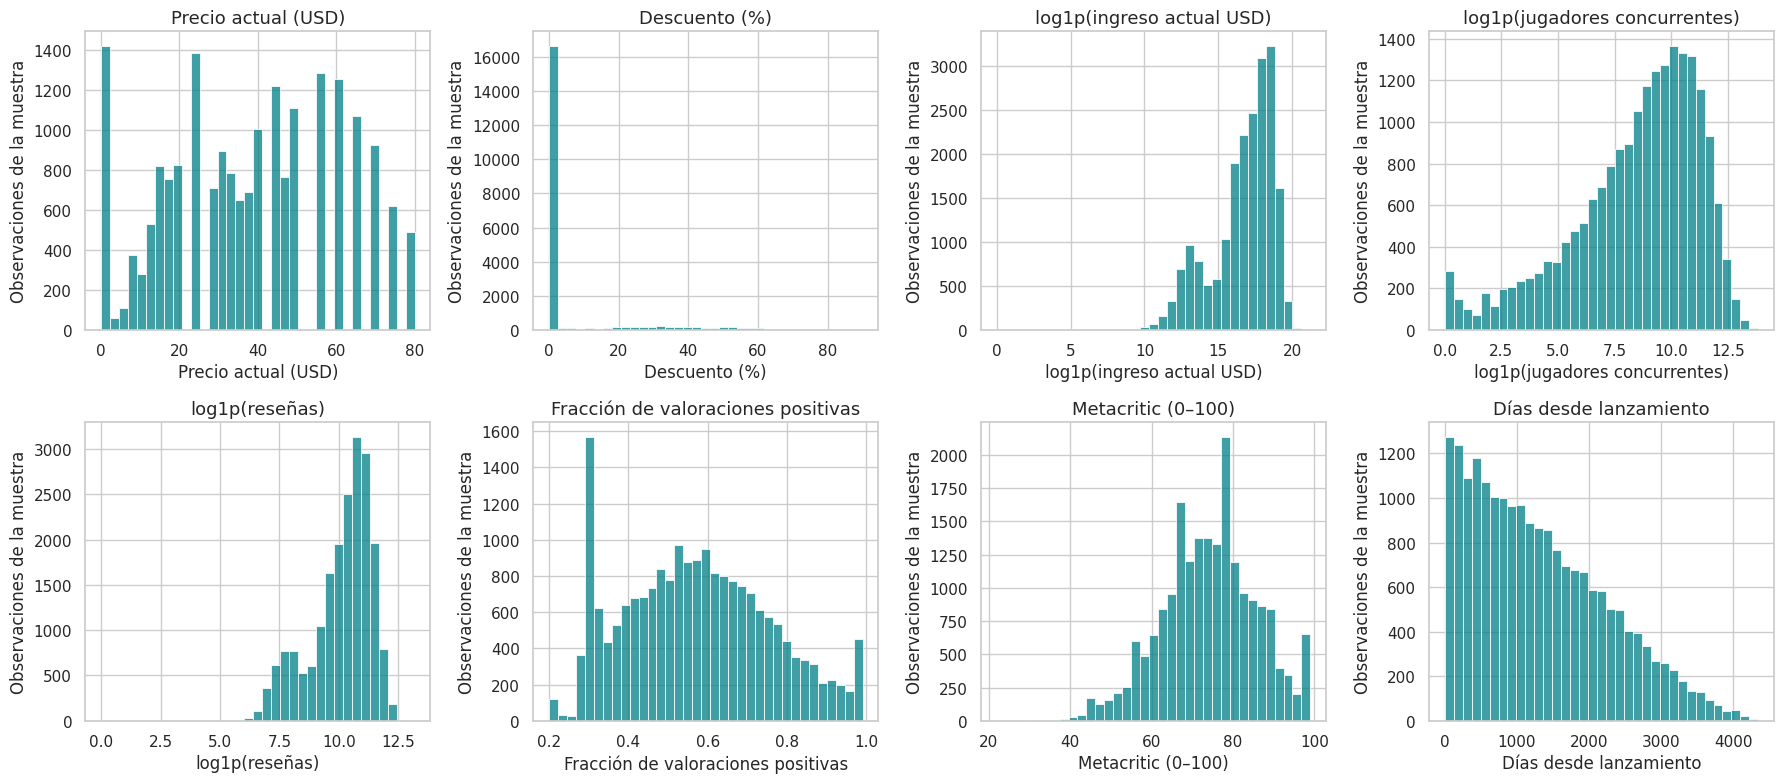

In [ ]:
# Construir una muestra acotada y mantener unido el bloque de los ocho histogramas.
eda_base_fraction = min(1.0, MAX_PLOT_ROWS / BASE_ROWS)
eda_base_pdf = base.select("obs_date", "platform", "genre", "publisher_tier", "publisher", *EDA_BASE_COLS).sample(
    withReplacement=False, fraction=eda_base_fraction, seed=SEED).limit(MAX_PLOT_ROWS).toPandas()

print(f"Muestra para gráficas: {len(eda_base_pdf):,} de {BASE_ROWS:,} registros limpios.")

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
eda_base_plot_specs = [
    ("current_price_usd", False, "Precio actual (USD)"), ("discount_pct", False, "Descuento (%)"),
    ("estimated_revenue_usd", True, "log1p(ingreso actual USD)"), ("concurrent_players", True, "log1p(jugadores concurrentes)"),
    ("review_count", True, "log1p(reseñas)"), ("steam_rating_pct", False, "Fracción de valoraciones positivas"),
    ("metacritic_score", False, "Metacritic (0–100)"), ("days_since_release", False, "Días desde lanzamiento")]

for ax, (column, log_scale, title) in zip(axes.flat, eda_base_plot_specs):
    values = eda_base_pdf[column].dropna()
    sns.histplot(np.log1p(values) if log_scale else values, bins=35, ax=ax, color="#007F86")
    ax.set(title=title, xlabel=title, ylabel="Observaciones de la muestra")
plt.tight_layout()
plt.show()

**Lectura de los histogramas.**

1. Precio actual (USD)

Los precios presentan una distribución irregular, con concentraciones en determinados importes, en lugar de distribuirse uniformemente entre 0 y aproximadamente 80 USD. Las barras separadas y los picos sugieren precios fijados en escalones comerciales.

La concentración en 0 USD incluye juegos gratuitos, como se comprobó en la revisión anterior. En el dataset completo, la media es 38.07 USD y la mediana 37.99 USD, de modo que el precio central se sitúa alrededor de 38 USD.

2. Descuento (%)

La característica dominante es la concentración en 0 % y los descuentos aparecen con mucha menor frecuencia y llegan hasta 90 %.
Esto era de esperarse con los resultados tanto de la mediana como el percentil 75 que son cero.

3. log1p(ingreso actual USD)

Los ingresos abarcan magnitudes muy diferentes, con la transformación logaritmica se comprimen esas diferencias y permite visualizar conjuntamente ingresos pequeños y grandes. El eje horizontal está en escala logaritmica, por lo que sus valores no deben leerse directamente como dólares.

En la escala original, la media del ingreso es aproximadamente 56.45 millones de USD, mientras que la mediana es 28.93 millones. La media considerablemente superior a la mediana indica que los ingresos altos elevan el promedio.

4. log1p(jugadores concurrentes)

La muestra concentra numerosas observaciones con miles o decenas de miles de jugadores, mientras que también aparecen registros con actividad muy baja o nula.

En los datos completos, la mediana es 8,379 jugadores y la media aproximadamente 34,040, esta diferencia indica que algunas observaciones con comunidades muy grandes elevan el promedio y el máximo supera 2.4 millones de jugadores concurrentes.

Aunque el histograma transformado concentra sus barras hacia la derecha, en la escala original los valores excepcionalmente altos producen una cola hacia los valores grandes.

5. log1p(reseñas)

La mayor concentración aparece en niveles que, al volver a la escala original, corresponden a decenas de miles de reseñas. También existe una cola hacia juegos u observaciones con pocas reseñas.

Un número alto de reseñas indica mayor volumen de opiniones, pero no necesariamente mejor reputación: para interpretar su calidad debe observarse también la fracción de valoraciones positivas.

6. Fracción de valoraciones positivas

La distribución se concentra principalmente alrededor de 0.5 a 0.7, es decir, entre 50 % y 70 % de valoraciones positivas. La media del conjunto completo es aproximadamente 56.95 % y la mediana 56.4 %.

También se observan acumulaciones alrededor de 0.3 y cerca del extremo superior. Esos picos indican valores especialmente frecuentes, aunque la gráfica por sí sola no permite determinar si responden a reglas específicas del simulador.

El nombre steam_rating_pct puede generar confusión: aquí está expresado como fracción entre 0 y 1. Por ejemplo, 0.6 representa 60 %, no 0.6 %.

7. Metacritic (0 - 100)

Las puntuaciones se concentran principalmente entre 60 y 90 puntos, con mayor frecuencia alrededor de los valores centrales de ese intervalo. La media es 73.92 y la mediana 74, lo que sitúa el centro de la distribución cerca de 74 puntos.

Las puntuaciones bajas son menos frecuentes en metacritic que en steam. Sin embargo, esta variable refleja una valoración distinta de la fracción de reseñas positivas de usuarios, por lo que, sus escalas y significados no son intercambiables.

8. Días desde lanzamiento

La mediana es 1,151 días, aproximadamente 3.2 años, y la media 1,313 días, unos 3.6 años. El máximo alcanza 4,380 días, aproximadamente 12 años.

La distribución tiene una cola hacia antigüedades elevadas. Esto describe la edad de los juegos cuando fueron observados; no equivale a contar cuántos videojuegos se lanzaron en cada año.

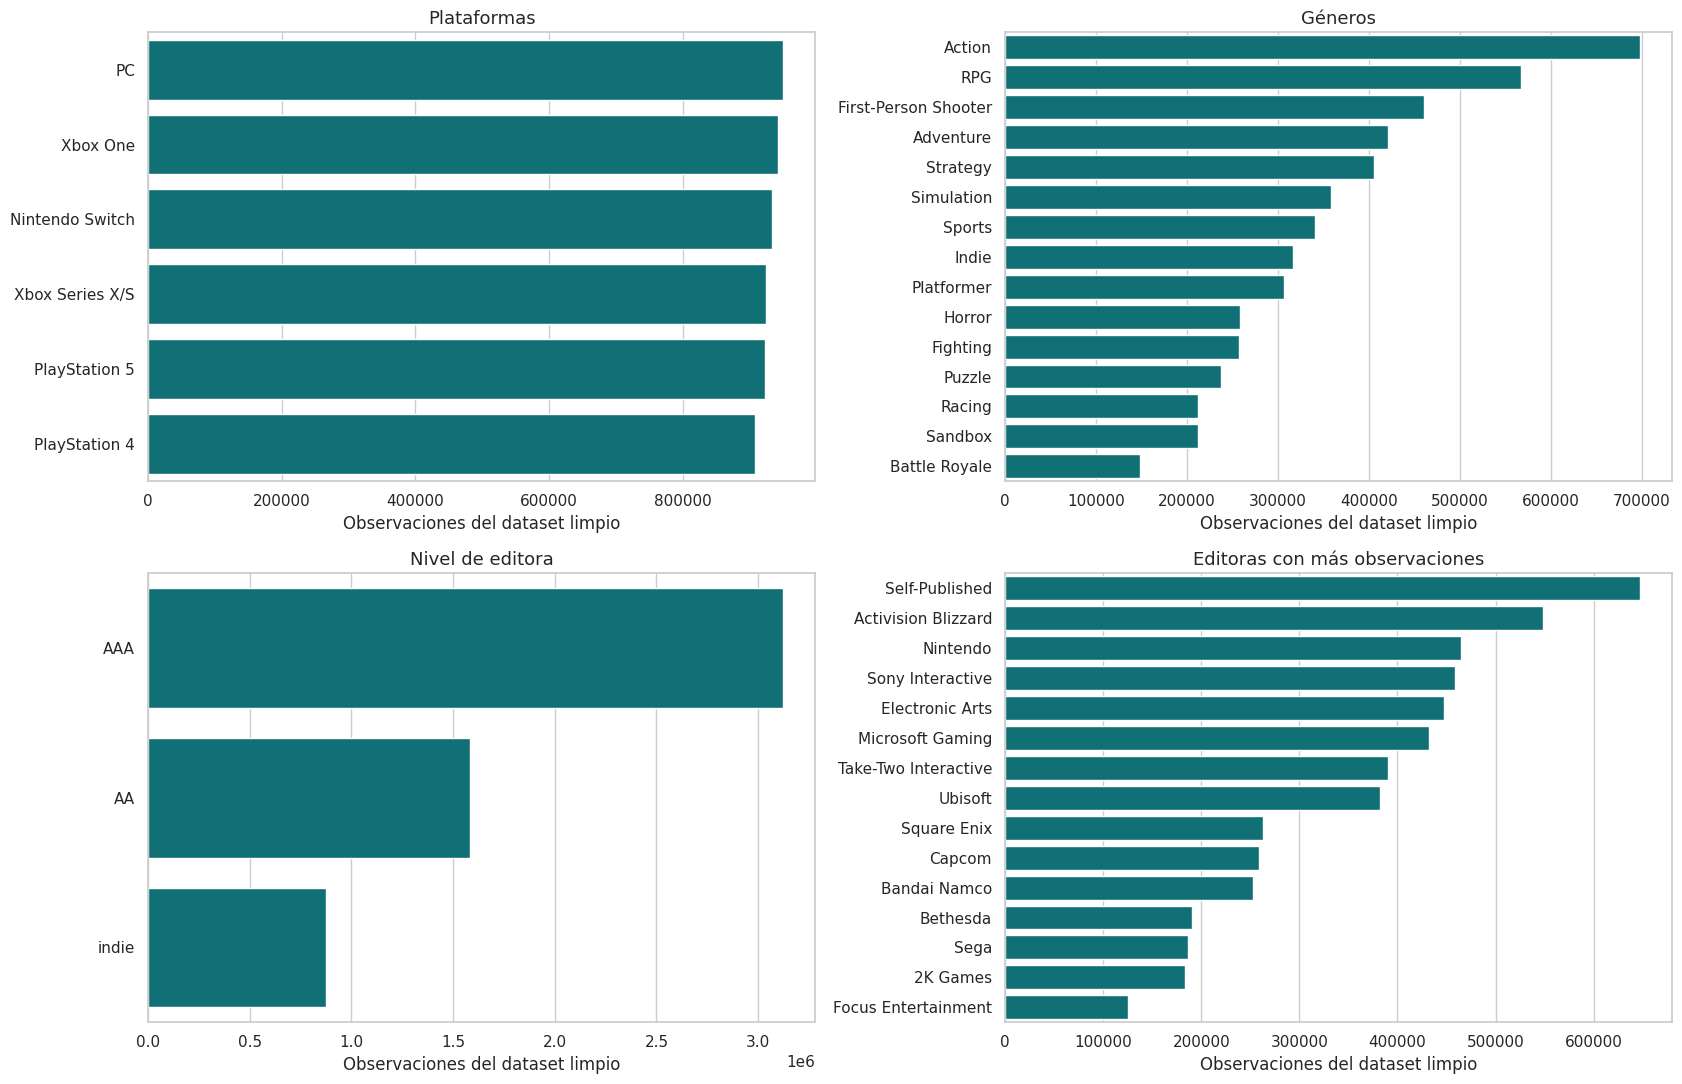

In [ ]:
# Resumir categorías en Spark sobre todos los registros limpios.
def eda_base_category_summary(column, limit=15):
    return (base.groupBy(column).agg(F.count("*").alias("observaciones"),
        F.avg("estimated_revenue_usd").alias("ingreso_medio_usd"))
        .orderBy(F.desc("observaciones")).limit(limit).toPandas())

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
for ax, column, title in zip(axes.flat, ["platform", "genre", "publisher_tier", "publisher"],
                            ["Plataformas", "Géneros", "Nivel de editora", "Editoras con más observaciones"]):
    eda_base_category_pdf = eda_base_category_summary(column)
    sns.barplot(data=eda_base_category_pdf, x="observaciones", y=column, ax=ax, color="#007F86")
    ax.set(title=title, xlabel="Observaciones del dataset limpio", ylabel="")
plt.tight_layout()
plt.show()

**Representación por categorías.**

1. Plataformas

Las seis plataformas tienen cantidades de observaciones relativamente similares, aproximadamente entre 900,000 y 950,000 registros cada una. PC presenta la mayor frecuencia y PlayStation 4 la menor, pero las diferencias son moderadas.

Esto indica una representación bastante equilibrada por plataforma dentro del dataset. Sin embargo, no demuestra igualdad en número de juegos únicos, jugadores, ingresos ni cuota de mercado: la gráfica solo cuenta observaciones.

2. Géneros

La representación es desigual. Action y RPG encabezan las frecuencias, seguidos por First-Person Shooter, Adventure y Strategy. En el otro extremo, Battle Royale presenta la menor cantidad de registros entre los géneros mostrados.

Esto significa que los análisis globales reciben una mayor contribución de los géneros más frecuentes. También conviene tener presente ese desequilibrio al interpretar el desempeño agregado del modelo, porque puede ocultar diferencias entre géneros.

3. Nivel de editora

El nivel AAA domina con aproximadamente 3.1 millones de observaciones; le siguen AA, con alrededor de 1.6 millones, e indie, con cerca de 0.9 millones.

En términos aproximados, representan 56 %, 28 % y 16 % del dataset, respectivamente. Por tanto, los resultados generales están más influidos por las observaciones AAA.

4. Editoras con más observaciones

La categoría Self-Published encabeza el conteo, seguida por Activision Blizzard. Después aparecen Nintendo, Sony Interactive, Electronic Arts y Microsoft Gaming, entre otras.

Self-Published agrupa títulos autopublicados, es decir, no representa necesariamente una sola empresa comparable con las demás. Una mayor frecuencia puede deberse a más juegos, más combinaciones de plataforma y tienda o más registros temporales y no implica automáticamente mayores ingresos ni más títulos únicos.

In [ ]:
# Comparar ingreso medio por observación, además de las frecuencias anteriores.
eda_base_platform_income = base.groupBy("platform").agg(F.avg("estimated_revenue_usd").alias("ingreso_medio_usd")).orderBy(F.desc("ingreso_medio_usd")).toPandas()
display(eda_base_platform_income)

,platform,ingreso_medio_usd
0,PlayStation 5,6.110302e+07
1,Xbox Series X/S,5.864115e+07
2,PC,5.792237e+07
3,Nintendo Switch,5.778986e+07
4,PlayStation 4,5.236545e+07
5,Xbox One,5.086865e+07


**Comparación por plataforma.**

Los resultados de esta tabla están expresados en miles de milloes, se observa que playstation pese a tener las menores observaciones comparado con las otras plataformas, su ingreso medio en ps5 es el mayor, seguido de xbox series X/S (sin embargo están contabilizando a la vez dos consolas diferentes) y después está PC. PS4 aparece nuevamente con un ingreso considerablemente alto.

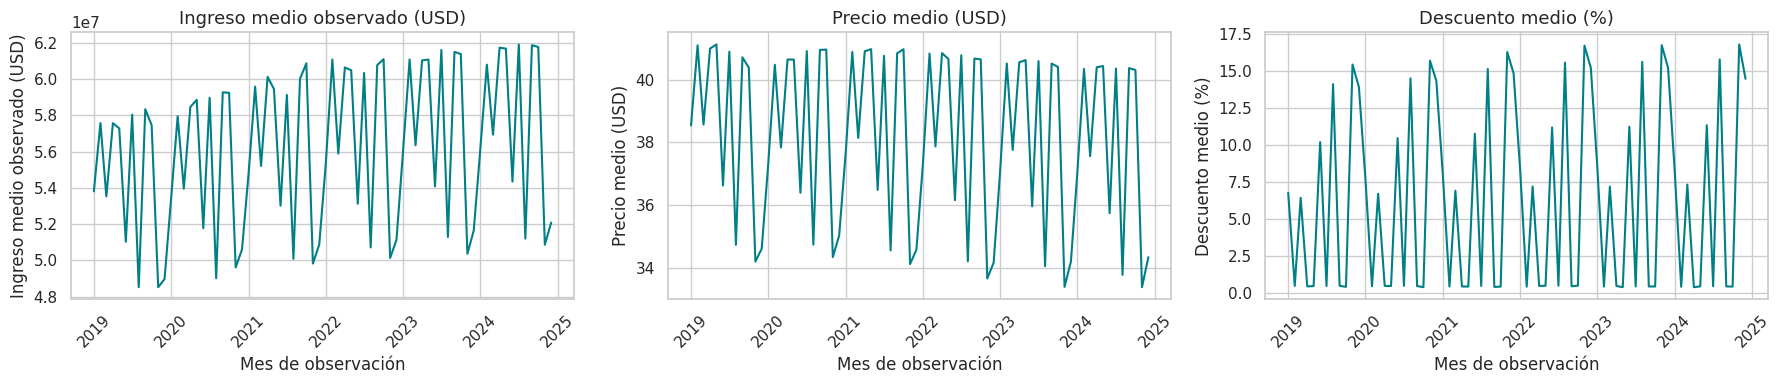

In [ ]:
# Agregar por mes en Spark y representar las series del dataset limpio completo.
eda_base_monthly_pdf = (base.withColumn("mes", F.trunc("obs_date", "month")).groupBy("mes")
    .agg(F.count("*").alias("observaciones"), F.avg("estimated_revenue_usd").alias("ingreso_medio_usd"),
         F.avg("current_price_usd").alias("precio_medio_usd"), F.avg("discount_pct").alias("descuento_medio_pct"))
    .orderBy("mes").toPandas())
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, column, title in zip(axes, ["ingreso_medio_usd", "precio_medio_usd", "descuento_medio_pct"],
                            ["Ingreso medio observado (USD)", "Precio medio (USD)", "Descuento medio (%)"]):
    ax.plot(pd.to_datetime(eda_base_monthly_pdf["mes"]), eda_base_monthly_pdf[column], color="#007F86")
    ax.set(title=title, xlabel="Mes de observación", ylabel=title)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Lectura temporal.**

1. Ingreso medio observado por mes

El ingreso medio presenta fluctuaciones recurrentes, aproximadamente entre 48 y 62 millones de USD por observación. Los picos de los últimos años son superiores a los de los primeros, lo que sugiere una tendencia positiva en sus niveles máximos mensuales.

Sin embargo, las caídas periódicas son pronunciadas, por lo que la evolución no es un crecimiento continuo. El patrón repetitivo sugiere una estructura temporal recurrente dentro de la simulación.

2. Precio medio por mes

El precio medio fluctúa aproximadamente entre 33 y 41 USD, con descensos que reaparecen a lo largo del periodo. Sus niveles superiores permanecen relativamente estables y algunos mínimos posteriores son algo menores.

El comportamiento es compatible con periodos de promociones que reducen el promedio. No obstante, también puede influir qué juegos aparecen en cada mes.

Al comparar esta gráfica con la siguiente, se aprecia una correspondencia visual entre varios aumentos del descuento medio y caídas del precio medio.

3. Descuento medio por mes

El descuento medio alterna entre meses con valores muy bajos y picos que alcanzan aproximadamente 15 - 17 %. La repetición de estos aumentos indica que las promociones se concentran en determinados periodos, por ejemplo a mitad del año (verano) y finales de año (navidad).

Esto es consistente con el histograma: predominan observaciones sin descuento, pero existen periodos en los que las promociones elevan el promedio mensual.

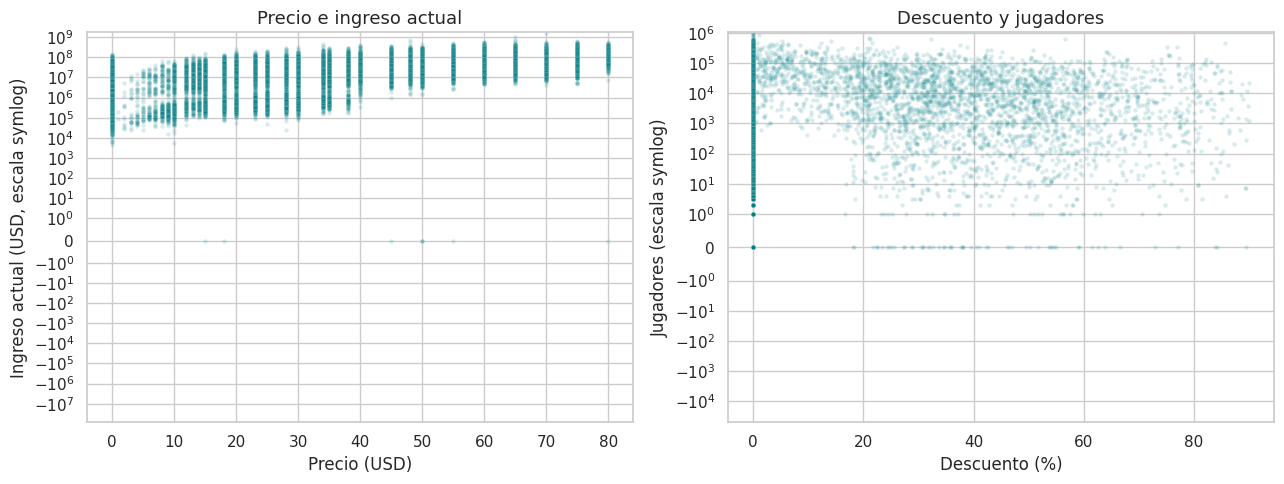

In [ ]:
# Explorar relaciones contemporáneas en la muestra del dataset limpio.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=eda_base_pdf, x="current_price_usd", y="estimated_revenue_usd", s=10, alpha=0.15, ax=axes[0])
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set(title="Precio e ingreso actual", xlabel="Precio (USD)", ylabel="Ingreso actual (USD, escala symlog)")
sns.scatterplot(data=eda_base_pdf, x="discount_pct", y="concurrent_players", s=10, alpha=0.15, ax=axes[1])
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set(title="Descuento y jugadores", xlabel="Descuento (%)", ylabel="Jugadores (escala symlog)")
plt.tight_layout()
plt.show()

**Relaciones entre variables actuales.**

1. Precio e ingreso actual

La nube de puntos muestra una asociación positiva general, donde los precios más altos tienden a acompañarse de ingresos mayores. Sin embargo, para un mismo precio existe una dispersión amplia de ingresos, por lo que el precio por sí solo no explica el resultado.

Las franjas verticales corresponden a precios que se repiten con frecuencia. En precio cero también aparecen ingresos positivos: el dataset permite esa combinación, aunque la gráfica no identifica su mecanismo de monetización.

2. Descuento y jugadores

No se observa un aumento claro y uniforme de jugadores conforme crece el descuento, ya que, para un mismo porcentaje existe una variación considerable en actividad.

En descuento cero aparece una franja vertical muy densa porque esa condición domina el dataset. Allí existen tanto observaciones con pocos jugadores como otras con comunidades muy grandes.

Los descuentos elevados tienen menos observaciones y también presentan resultados diversos. Por tanto, la gráfica no respalda una regla sencilla como “más descuento produce más jugadores”. Tampoco permite medir el efecto de una promoción sin considerar otras diferencias entre juegos y fechas.

In [ ]:
# Resumir los intervalos reales entre observaciones consecutivas de cada serie.
eda_observation_window = Window.partitionBy(*SERIES_COLS).orderBy("obs_date")
eda_observation_gaps = (base.select(*SERIES_COLS, "obs_date")
    .withColumn("previous_obs_date", F.lag("obs_date").over(eda_observation_window))
    .withColumn("observation_gap_days", F.datediff("obs_date", "previous_obs_date"))
    .where(F.col("observation_gap_days").isNotNull()))
eda_observation_gaps.agg(
    F.count("*").alias("intervalos_observados"),
    F.min("observation_gap_days").alias("min_dias"),
    F.avg("observation_gap_days").alias("media_dias"),
    F.percentile_approx("observation_gap_days", [0.25, 0.5, 0.75], 10_000).alias("cuartiles_dias_aprox"),
    F.max("observation_gap_days").alias("max_dias")
).show(truncate=False)

+---------------------+--------+-----------------+--------------------+--------+
|intervalos_observados|min_dias|media_dias       |cuartiles_dias_aprox|max_dias|
+---------------------+--------+-----------------+--------------------+--------+
|5556072              |1       |6.989453700384012|[2, 5, 9]           |95      |
+---------------------+--------+-----------------+--------------------+--------+



**Frecuencia real de observación.**

Aproximadamente la mitad de los intervalos dura cinco días o menos, mientras que algunos son considerablemente más largos. Estos intervalos largos elevan la media por encima de la mediana.

Para el modelo esto implica que cuatro observaciones futuras no equivalen a cuatro semanas exactas, sino que la frecuencia de registro es irregular, por eso el notebook calcula la fecha objetivo y el horizonte real de cada predicción.

## 6. Objetivo: ingreso cuatro observaciones adelante
Se ordena cada serie **juego/plataforma/tienda** por `obs_date`. `lead(estimated_revenue_usd, 4)` recupera el ingreso de la cuarta fila futura y `lead(obs_date, 4)` su fecha real.

Se excluyen las últimas cuatro filas de cada serie, o todas sus filas si tiene cuatro registros o menos.

`horizon_days` describe los días entre la observación actual y su etiqueta. Esta duración y `target_date` son información futura: sirven para auditar y separar períodos, pero **no entran como predictores**.

El objetivo es el ingreso de una observación futura, no el ingreso acumulado.

In [ ]:
# Reconstruir ingreso y fecha de la cuarta observación futura de cada serie.
series_counts = base.groupBy(*SERIES_COLS).count()
series_stats = series_counts.agg(
    F.count("*").alias("series"),
    F.sum(F.when(F.col("count") <= HORIZON_OBSERVATIONS, 1).otherwise(0)).alias("series_cortas"),
    F.sum(F.greatest(F.col("count") - F.lit(HORIZON_OBSERVATIONS), F.lit(0))).alias("etiquetas_esperadas")
).first().asDict()
EXPECTED_LABELLED_ROWS = int(series_stats["etiquetas_esperadas"])

future_window = Window.partitionBy(*SERIES_COLS).orderBy("obs_date")
labelled_all = (base
    .withColumn("label_usd", F.lead("estimated_revenue_usd", HORIZON_OBSERVATIONS).over(future_window))
    .withColumn("target_date", F.lead("obs_date", HORIZON_OBSERVATIONS).over(future_window))
    .withColumn("horizon_days", F.datediff("target_date", "obs_date")))

LABELLED_PATH = PARQUET_DIR / "labelled_4obs"
labelled_all.where(F.col("label_usd").isNotNull()).write.mode("overwrite").parquet(str(LABELLED_PATH))
labelled = spark.read.parquet(str(LABELLED_PATH)).withColumn("label_log", F.log1p("label_usd"))
LABELLED_ROWS = labelled.count()

if LABELLED_ROWS != EXPECTED_LABELLED_ROWS:
    raise RuntimeError(f"Etiquetas inesperadas: {LABELLED_ROWS:,}; se esperaban {EXPECTED_LABELLED_ROWS:,} según los tamaños de las series.")

horizon_stats = labelled.agg(
    F.min("horizon_days").alias("min_dias"),
    F.avg("horizon_days").alias("media_dias"),
    F.percentile_approx("horizon_days", [0.25, 0.5, 0.75], 10_000).alias("cuartiles_dias"),
    F.max("horizon_days").alias("max_dias"),
    F.sum(F.when(F.col("target_date").isNull() | F.col("horizon_days").isNull()
        | (F.col("target_date") <= F.col("obs_date")) | (F.col("horizon_days") <= 0), 1)
        .otherwise(0)).alias("fechas_invalidas")
).first().asDict()

if horizon_stats["fechas_invalidas"]:
    raise RuntimeError("Todas las etiquetas deben tener una fecha objetivo posterior a la observación.")

horizon_distribution = (labelled.groupBy("horizon_days").count()
    .withColumn("porcentaje", 100.0 * F.col("count") / F.lit(LABELLED_ROWS))
    .orderBy("horizon_days"))

In [ ]:
print(f"Con etiqueta a {HORIZON_OBSERVATIONS} observaciones: {LABELLED_ROWS:,} ({LABELLED_ROWS / BASE_ROWS:.2%} de los limpios)")
print(f"Sin cuatro observaciones futuras: {BASE_ROWS - LABELLED_ROWS:,}")
print(f"Series: {series_stats['series']:,}; con cuatro registros o menos: {series_stats['series_cortas']:,}")
print(f"Control de etiquetas: {LABELLED_ROWS:,} = suma(max(registros por serie - {HORIZON_OBSERVATIONS}, 0))")

Con etiqueta a 4 observaciones: 5,470,635 (97.96% de los limpios)
Sin cuatro observaciones futuras: 114,071
Series: 28,634; con cuatro registros o menos: 338
Control de etiquetas: 5,470,635 = suma(max(registros por serie - 4, 0))


Muestra cuántas filas conservaron etiqueta, los resultados son:

- Con etiqueta: 5,470,635.
- Cobertura sobre datos limpios: 97.96 %.
- Sin suficientes observaciones futuras: 114,071.
- Series distintas: 28,634.
- Series con cuatro registros o menos: 338.

Las series con cuatro registros o menos pierden todas sus filas. Las demás pierden las últimas cuatro, ya que son filas cuyo futuro requerido no está disponible.

In [ ]:
display(pd.DataFrame([{
    "min_dias": horizon_stats["min_dias"], "p25_dias_aprox": horizon_stats["cuartiles_dias"][0],
    "mediana_dias_aprox": horizon_stats["cuartiles_dias"][1], "media_dias": horizon_stats["media_dias"],
    "p75_dias_aprox": horizon_stats["cuartiles_dias"][2], "max_dias": horizon_stats["max_dias"]
}]))

,min_dias,p25_dias_aprox,mediana_dias_aprox,media_dias,p75_dias_aprox,max_dias
0,4,19,26,27.95792,35,149


La tabla anterior muestra los rangos en los que se encuentran separadas la primera con la cuarta observación, en el caso del valor mínimo, este es muy pequeño, ya que se encuentran separados 4 días, el 25% de los datos tiene una separación de 19 días o menor, la mitad de los datos es de 26 días, lo que está realmente cerca de 4 semanas o 28 días, y solo un cuarto de los datos presenta días superiores a 35, teniendo un valor máximo de 149 días de diferencia.

Distribución del horizonte en días: todos los registros etiquetados.


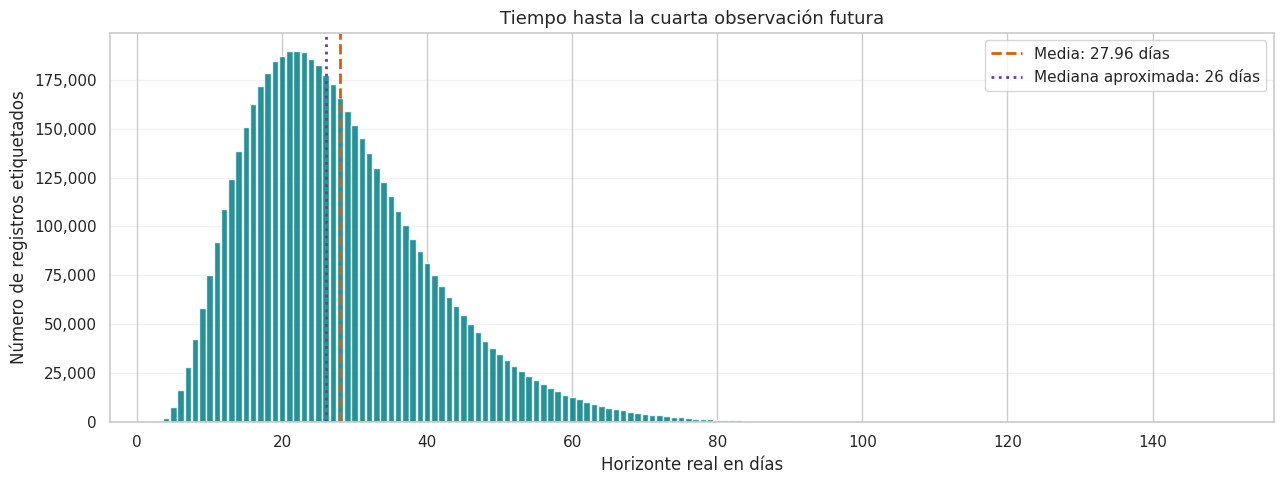

Ejemplos del ingreso actual y su etiqueta futura:


,game_id,platform_code,storefront,obs_date,target_date,horizon_days,estimated_revenue_usd,label_usd
0,G00000004,ps4,PlayStation Store,2022-11-14,2022-12-16,32,$0.00,"$116,093.00"
1,G00000004,ps4,PlayStation Store,2022-11-17,2022-12-19,32,"$36,833.00","$72,446.00"
2,G00000004,ps4,PlayStation Store,2022-11-20,2022-12-21,31,"$53,635.00","$94,421.00"
3,G00000004,ps4,PlayStation Store,2022-11-22,2022-12-30,38,"$91,563.00","$142,806.00"
4,G00000004,ps4,PlayStation Store,2022-12-16,2023-01-01,16,"$116,093.00","$139,344.00"


In [ ]:
# Convertir únicamente la distribución agregada, no todo el dataset.
horizon_pdf = (
    horizon_distribution
    .orderBy("horizon_days")
    .toPandas()
)

print("Distribución del horizonte en días: todos los registros etiquetados.")

# Cada barra representa el número de registros con ese horizonte.
fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    horizon_pdf["horizon_days"],
    horizon_pdf["count"],
    width=0.9,
    color="#007F86",
    alpha=0.85
)

ax.axvline(
    horizon_stats["media_dias"],
    color="#D95F02",
    linestyle="--",
    linewidth=2,
    label=f'Media: {horizon_stats["media_dias"]:.2f} días'
)

ax.axvline(
    horizon_stats["cuartiles_dias"][1],
    color="#6A3D9A",
    linestyle=":",
    linewidth=2,
    label=f'Mediana aproximada: {horizon_stats["cuartiles_dias"][1]:.0f} días'
)

ax.set(
    title="Tiempo hasta la cuarta observación futura",
    xlabel="Horizonte real en días",
    ylabel="Número de registros etiquetados"
)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

# Convertir únicamente cinco ejemplos a pandas.
print("Ejemplos del ingreso actual y su etiqueta futura:")

examples_pdf = (
    labelled.select(
        *SERIES_COLS,
        "obs_date",
        "target_date",
        "horizon_days",
        "estimated_revenue_usd",
        "label_usd"
    )
    .limit(5)
    .toPandas()
)

display(
    examples_pdf.style.format({
        "horizon_days": "{:.0f}",
        "estimated_revenue_usd": "${:,.2f}",
        "label_usd": "${:,.2f}"
    })
)

En esta grafica se observa la distribución que comentabamos con la tabla pasada, donde el valor minimo es de 4 días, la mediana de 26 y la media de 28 días, lo que es lo ideal que buscamos, porque se predice el precio en la cuarta semana (en este caso se utiliza observación, precisamente por que la distribución presenta sesgos y pocos casos donde se cumpla exactamente 28 días de separación).

Aquí podemos ver que existen pocos casos cuya diferencias en los días observados entre la primera y cuarta observacion son realmente grandes, por ejemplo superiores a un mes, dos meses e incluso el mayor caso con 149 días.

## 7. Train-validation split temporal configurable
Se acumula el número de registros elegibles por día y se eligen los cortes más cercanos a las proporciones solicitadas, sin fragmentar una fecha. Luego se excluyen las observaciones de entrenamiento cuyo objetivo se conoce dentro de validación y las de validación cuyo objetivo se conoce dentro de prueba, así se asegura que no exista fuga de información entre conjuntos que sesgue el resultado del modelo.

`TrainValidationSplit` de MLlib divide aleatoriamente; aquí se realiza su función de selección de hiperparámetros mediante un **split temporal explícito**, sin validación cruzada. La misma entidad puede aparecer en períodos distintos: la pregunta es anticipar sus ingresos futuros, no medir generalización a juegos totalmente nuevos. El conjunto de prueba se reserva hasta fijar la configuración ganadora.

In [ ]:
# Solo se recopila una fila por fecha, nunca los registros completos.
date_counts = labelled.groupBy("obs_date").count().orderBy("obs_date").limit(100_001).collect()
cumulative = list(accumulate(row["count"] for row in date_counts))

train_end_index = min(range(len(date_counts) - 2),
                      key=lambda i: abs(cumulative[i] / LABELLED_ROWS - TRAIN_RATIO))
val_end_index = min(range(train_end_index + 1, len(date_counts) - 1),
                    key=lambda i: abs(cumulative[i] / LABELLED_ROWS - (TRAIN_RATIO + VAL_RATIO)))

VAL_START = date_counts[train_end_index + 1]["obs_date"]
TEST_START = date_counts[val_end_index + 1]["obs_date"]
train_nominal = labelled.where(F.col("obs_date") < F.lit(VAL_START))
val_nominal = labelled.where((F.col("obs_date") >= F.lit(VAL_START)) & (F.col("obs_date") < F.lit(TEST_START)))

test = labelled.where(F.col("obs_date") >= F.lit(TEST_START))
train = train_nominal.where(F.col("target_date") < F.lit(VAL_START))
val = val_nominal.where(F.col("target_date") < F.lit(TEST_START))

split_rows = []
for name, requested, nominal, purged in [
    ("train", TRAIN_RATIO, train_nominal, train),
    ("val", VAL_RATIO, val_nominal, val),
    ("test", TEST_RATIO, test, test)
]:
    before = nominal.count()
    stats = purged.agg(F.count("*").alias("n"), F.min("obs_date").alias("inicio"),
                       F.max("obs_date").alias("fin"), F.max("target_date").alias("ultima_etiqueta")).first().asDict()
    next_cut = VAL_START if name == "train" else TEST_START if name == "val" else None
    split_rows.append({"particion": name, "proporcion_solicitada": requested,
        "registros_antes": before, "porcentaje_antes": 100 * before / LABELLED_ROWS,
        "registros_despues": stats["n"], "excluidos_por_horizonte": before - stats["n"], **{k:stats[k] for k in ("inicio", "fin", "ultima_etiqueta")}})
split_pdf = pd.DataFrame(split_rows)
retained_total = int(split_pdf["registros_despues"].sum())
split_pdf["porcentaje_despues_sobre_retenidos"] = 100 * split_pdf["registros_despues"] / retained_total
N_TRAIN, N_VAL, N_TEST = [int(x) for x in split_pdf["registros_despues"]]

In [ ]:
display(split_pdf)

,particion,proporcion_solicitada,registros_antes,porcentaje_antes,registros_despues,excluidos_por_horizonte,inicio,fin,ultima_etiqueta,porcentaje_despues_sobre_retenidos
0,train,0.8,4376172,79.993858,4276285,99887,2019-01-02,2024-02-14,2024-02-19,81.234349
1,val,0.1,547866,10.014669,441252,106614,2024-02-20,2024-07-12,2024-07-16,8.382233
2,test,0.1,546597,9.991473,546597,0,2024-07-17,2024-12-26,2024-12-30,10.383417


Esta tabla nos muestra el conjunto, cuantos registros había antes y cuanto porcentaje representaba de los registros totales. También muestra como cambian estos números después de excluir las observaciones que se pasaban entre conjuntos (de train a val y de val a test) así como cuantos valores retiró.

- Para train fueron 99,887 observaciones y su periodo de observación abarca del 2 de enero de 2019 al 14 de febrero de 2024, de este conjunto su porcentaje aumentó cerca de un 1.2%.

- Para val, sus exclusiones fueron de 106,614 observaciones, más que las de train, y sus fechas que abarca son del 20 de febrero del 2024 al 12 de julio de 2024. Su porcentaje de todo el dataset bajó cerca de 1.7%

- Para test, no contó con exclusiones de este tipo porque no hay ningún conjunto después de este, sus fechas abarcan del 17 de julio de 2024 al 26 de diciembre del 2024 y como los porcentajes de proporcion de cada conjunto se modificaron este igual sufrió un aumento de cerca de 0.4%.

## 8. EDA de entrenamiento para modelado
Este bloque utiliza exclusivamente `train`, después de construir la etiqueta y aplicar el split temporal. Las estadísticas abarcan todo el entrenamiento inicial y las gráficas utilizan una muestra propia de hasta `MAX_PLOT_ROWS`, con semilla fija. No se reutiliza la muestra descriptiva de `base` ni se consultan validación o prueba para decidir características.

Se examinan la distribución del ingreso futuro, su relación con el ingreso actual y las correlaciones entre variables. Estos resultados permiten interpretar asimetrías, la referencia de persistencia y las transformaciones del Pipeline, sin afirmar causalidad ni anticipar las métricas de prueba.

In [ ]:
# Definir las columnas del EDA de modelado y resumir todo el entrenamiento.
EDA_TRAIN_COLS = ["current_price_usd", "discount_pct", "estimated_revenue_usd", "concurrent_players", "review_count",
                  "steam_rating_pct", "metacritic_score", "days_since_release", "hype_score", "label_usd"]
train.select(*EDA_TRAIN_COLS).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show(truncate=False)

+-------+-----------------+------------------+---------------------+------------------+-----------------+------------------+------------------+------------------+------------------+--------------------+
|summary|current_price_usd|discount_pct      |estimated_revenue_usd|concurrent_players|review_count     |steam_rating_pct  |metacritic_score  |days_since_release|hype_score        |label_usd           |
+-------+-----------------+------------------+---------------------+------------------+-----------------+------------------+------------------+------------------+------------------+--------------------+
|count  |4276285          |4276285           |4276285              |4276285           |4276285          |4276285           |4276285           |4276285           |4276285           |4276285             |
|mean   |38.12943707411459|6.4771878628294965|5.60572572157714E7   |35533.497926822   |42284.46165047465|0.5698531138592361|73.94766602319537 |1235.1210433822816|15.312685886933245|5.67154

**Estadísticas para el modelado.**

La comparación entre estimated_revenue_usd y label_usd muestra que sus distribuciones tienen escalas parecidas, sus medianas son de aproximadamente 29.0 y 29.6 millones de USD, respectivamente. Sin embargo, esto no demuestra por sí solo cuánto cambia el ingreso de cada registro ni qué tan bien podrá predecirlo el modelo, para eso hay que revisar las métricas de predicción.

La asimetría de los ingresos ayuda a entender por qué el notebook entrena con log1p(label_usd), ya que esta transformación reduce la diferencia de escala entre ingresos típicos y muy altos. Las métricas finales en dólares siguen siendo necesarias para interpretar el tamaño práctico de los errores.

Por último, el count es igual en todas las columnas mostradas: 4,276,285 valores no nulos por columna en este resumen.

Muestra para modelado: 20,000 de 4,276,285 registros de entrenamiento.


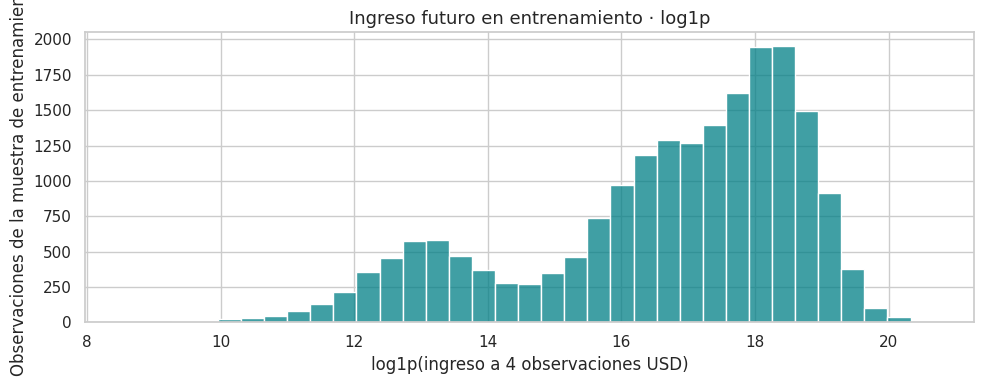

In [ ]:
# Crear una muestra exclusiva de entrenamiento y visualizar el target en log1p.
eda_train_fraction = min(1.0, MAX_PLOT_ROWS / N_TRAIN)
eda_train_pdf = train.select(*EDA_TRAIN_COLS).sample(
    withReplacement=False, fraction=eda_train_fraction, seed=SEED + 1).limit(MAX_PLOT_ROWS).toPandas()
print(f"Muestra para modelado: {len(eda_train_pdf):,} de {N_TRAIN:,} registros de entrenamiento.")

plt.figure(figsize=(10, 4))
sns.histplot(np.log1p(eda_train_pdf["label_usd"].dropna()), bins=35, color="#007F86")
plt.title("Ingreso futuro en entrenamiento · log1p")
plt.xlabel("log1p(ingreso a 4 observaciones USD)")
plt.ylabel("Observaciones de la muestra de entrenamiento")
plt.tight_layout()
plt.show()

**Distribución del target.**

En las 20,000 observaciones de la muestra de entrenamiento, la mayor concentración se encuentra entre 16 y 19 en la escala `log1p`, con las barras más altas alrededor de 18. También aparece una agrupación menor cerca de 13, separada de la principal por una zona de menor frecuencia. Por lo tanto, la transformación comprime la escala de los ingresos, pero la distribución conserva diferencias entre grupos y no presenta una forma de campana simétrica.

Esto coincide con las estadísticas anteriores: el ingreso futuro tiene una media de aproximadamente 56.7 millones de USD, superior a su mediana de 29.6 millones, y llega a un máximo cercano a 1,954.6 millones. Los valores altos elevan la media en la escala original. Trabajar con el logaritmo reduce esas diferencias de escala durante el ajuste. Por último, el valor mínimo del target en todo este entrenamiento es de 1,765 USD, por lo que aquí no se observan ingresos futuros iguales a cero.

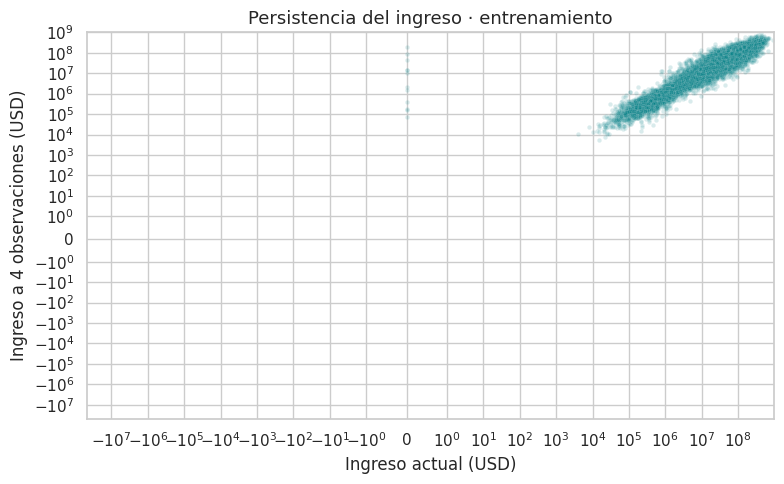

In [ ]:
# Comparar ingreso actual y futuro exclusivamente en la muestra de entrenamiento.
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=eda_train_pdf, x="estimated_revenue_usd", y="label_usd", s=10, alpha=0.15, ax=ax)
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("symlog", linthresh=1)
ax.set(title="Persistencia del ingreso · entrenamiento", xlabel="Ingreso actual (USD)", ylabel="Ingreso a 4 observaciones (USD)")
plt.tight_layout()
plt.show()

**Relación con la referencia de persistencia.**

La nube de puntos muestra una asociación positiva clara: las observaciones con ingresos actuales mayores suelen tener también ingresos futuros mayores. La concentración sigue una franja ascendente, aunque existe dispersión alrededor de ella; conocer el ingreso actual aporta información sobre el futuro, pero no permite anticiparlo de manera exacta.

También se observa una columna de puntos con ingreso actual igual a cero e ingreso futuro positivo. En esos casos, conservar el ingreso actual como predicción produciría una subestimación. La gráfica no permite determinar por qué se registraron esos ceros.

La relación observada justifica usar la persistencia como referencia: es una comparación exigente porque el ingreso actual ya está fuertemente relacionado con el objetivo.

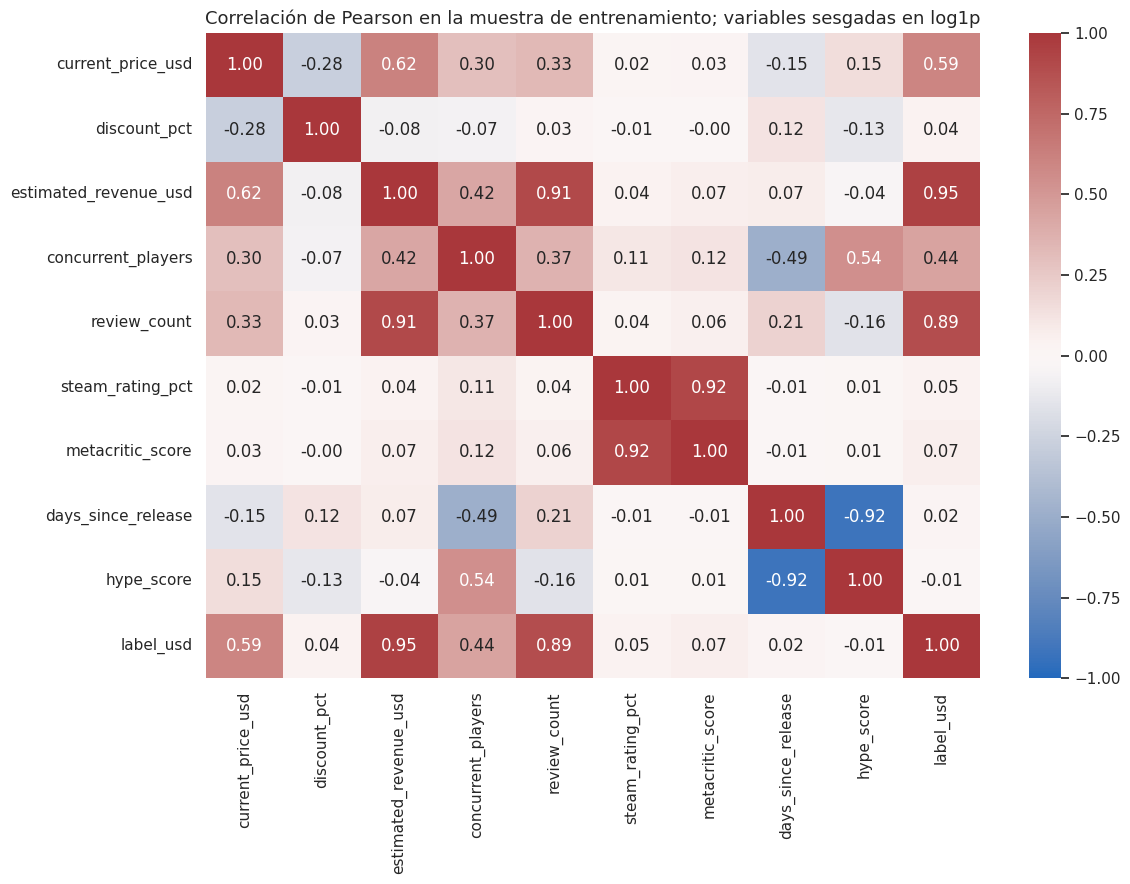

In [ ]:
# Correlaciones de Pearson en una copia de la muestra exclusiva de entrenamiento.
eda_train_corr_pdf = eda_train_pdf[EDA_TRAIN_COLS].copy()
for c in ["estimated_revenue_usd", "label_usd", "concurrent_players", "review_count", "days_since_release"]:
    eda_train_corr_pdf[c] = np.log1p(eda_train_corr_pdf[c])
plt.figure(figsize=(12, 9))
sns.heatmap(eda_train_corr_pdf.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Pearson en la muestra de entrenamiento; variables sesgadas en log1p")
plt.tight_layout()
plt.show()

**Interpretación de la matriz.**

El ingreso actual es la variable con mayor correlación con el ingreso futuro, con **0.95**, seguido del número de reseñas, con **0.89**. El precio actual presenta una asociación positiva de **0.59** y los jugadores concurrentes, de **0.44**. En esta muestra, los ingresos y la cantidad de reseñas están más asociados con el objetivo que las calificaciones, los descuentos o el hype, cuyas correlaciones con el ingreso futuro son cercanas a cero.

Entre los predictores también existen relaciones fuertes: ingreso actual y reseñas tienen una correlación de **0.91**, las calificaciones de Steam y Metacritic de **0.92**, y la antigüedad del juego y el hype de **−0.92**. Esto indica que algunas variables aportan información relacionada entre sí y da contexto al uso de regularización para controlar los coeficientes del modelo. La relación negativa entre antigüedad y hype muestra que, en la muestra, los juegos más antiguos tienden a tener menor hype.

Estas correlaciones corresponden a 20,000 observaciones de entrenamiento, con `log1p` aplicado a ingreso actual, ingreso futuro, jugadores, reseñas y antigüedad. Describen asociaciones lineales en esas escalas, más no demuestran causalidad ni miden la importancia individual de cada variable dentro de la regresión. Una correlación cercana a cero tampoco descarta relaciones no lineales o aportes al combinar variables.

## 9. Ingeniería de características y Pipeline de MLlib

Las gráficas anteriores muestran ingresos y conteos con escalas amplias, así como predictores relacionados entre sí. El Pipeline transforma con `log1p` el ingreso actual y los conteos seleccionados para reducir esas diferencias de escala. Además, representa el mes con seno y coseno para mantener la continuidad entre diciembre y enero, incorpora imputación por mediana y codifica las seis variables categóricas con `StringIndexer` y `OneHotEncoder`, reservando una categoría para valores nuevos.

Las medianas y categorías se aprenden únicamente con los 4,276,285 registros de entrenamiento inicial. Ese preprocesamiento se aplica también a validación y sus vectores se guardan en disco para reutilizarlos al comparar las cuatro regresiones. Así, las configuraciones se evalúan sobre la misma preparación de los datos. La regresión utiliza regularización y estandarización interna.

La etiqueta es `log1p(label_usd)`, es decir, el ingreso cuatro observaciones adelante en escala logarítmica. La fecha objetivo, la duración futura del horizonte y las etiquetas quedan fuera de los predictores. Para evaluar el resultado se aplica `expm1` y se recortan a cero las predicciones negativas. Las métricas en dólares permiten comprobar los errores que permanecen después de invertir el logaritmo, incluida la posible diferencia entre ajustar bien en escala logarítmica y hacerlo en la escala original.

In [ ]:
# Definir las transformaciones y las etapas del Pipeline antes de ajustarlo.
LOG_INPUT_COLS = ["estimated_revenue_usd", "concurrent_players", "review_count", "wishlist_count", "twitch_viewers_proxy", "days_since_release"]
LOG_OUTPUT_COLS = [f"log_{c}" for c in LOG_INPUT_COLS]
FEATURE_NUMERIC_COLS = [c for c in NUMERIC_COLS if c not in LOG_INPUT_COLS] + LOG_OUTPUT_COLS + ["month_sin", "month_cos"]
FUTURE_ONLY_COLS = {"label_usd", "label_log", "target_date", "horizon_days"}

if FUTURE_ONLY_COLS.intersection(FEATURE_NUMERIC_COLS + CATEGORICAL_COLS) or any(
    c.startswith("target_") for c in FEATURE_NUMERIC_COLS + CATEGORICAL_COLS
):
    raise ValueError("Las variables futuras no pueden entrar como predictores.")

feature_statement = "SELECT *, " + ", ".join(
    [f"LN(1.0 + `{c}`) AS `log_{c}`" for c in LOG_INPUT_COLS] + [
        "SIN(2.0 * PI() * MONTH(obs_date) / 12.0) AS month_sin",
        "COS(2.0 * PI() * MONTH(obs_date) / 12.0) AS month_cos"]
) + " FROM __THIS__"

feature_sql = SQLTransformer(statement=feature_statement)

# Si una variable está completamente vacía en entrenamiento, no hay mediana que estimar.
feature_counts = feature_sql.transform(train).agg(*[F.count(c).alias(c) for c in FEATURE_NUMERIC_COLS]).first().asDict()
empty_features = [c for c, n in feature_counts.items() if n == 0]

imputed_cols = [f"{c}_imp" for c in FEATURE_NUMERIC_COLS]
indexed_cols = [f"{c}_idx" for c in CATEGORICAL_COLS]
encoded_cols = [f"{c}_ohe" for c in CATEGORICAL_COLS]

preprocessing = Pipeline(stages=[
    feature_sql,
    Imputer(inputCols=FEATURE_NUMERIC_COLS, outputCols=imputed_cols, strategy="median", relativeError=0.01),
    StringIndexer(inputCols=CATEGORICAL_COLS, outputCols=indexed_cols, handleInvalid="keep", stringOrderType="alphabetAsc"),
    OneHotEncoder(inputCols=indexed_cols, outputCols=encoded_cols, handleInvalid="keep", dropLast=True),
    VectorAssembler(inputCols=imputed_cols + encoded_cols, outputCol="features", handleInvalid="error")
])

In [ ]:
# Aprender el preprocesamiento exclusivamente en train y reutilizar sus vectores.
preprocessor_model = preprocessing.fit(train)
VECTOR_COLS = ["features", "label_log", "label_usd", "estimated_revenue_usd"]
train_vectors = preprocessor_model.transform(train).select(*VECTOR_COLS).persist(StorageLevel.DISK_ONLY)
val_vectors = preprocessor_model.transform(val).select(*VECTOR_COLS).persist(StorageLevel.DISK_ONLY)

In [ ]:
print("Vectores de entrenamiento:", train_vectors.count(), "| Vectores de validación:", val_vectors.count())
print("Características numéricas:", len(FEATURE_NUMERIC_COLS), "| Categóricas:", len(CATEGORICAL_COLS))

Vectores de entrenamiento: 4276285 | Vectores de validación: 441252
Características numéricas: 26 | Categóricas: 6


**Características construidas.**

Se obtuvieron **4,276,285 vectores de entrenamiento** y **441,252 de validación**. Estos conteos coinciden con las particiones después de excluir etiquetas que cruzaban los cortes temporales, por lo que la transformación conserva todas las filas elegibles de ambos conjuntos.

Las entradas incluyen **26 características numéricas** y **6 categóricas**. Las numéricas incorporan las transformaciones logarítmicas y las dos componentes del mes; las categóricas se expanden mediante one-hot, de modo que estas 32 entradas no equivalen a 32 posiciones del vector final.

Validación utiliza las medianas y categorías aprendidas en entrenamiento. Aunque la auditoría previa no encontró valores faltantes en las columnas seleccionadas, la imputación queda incorporada en el Pipeline para procesar entradas posteriores. Ni la fecha objetivo ni los días que tardará en llegar la cuarta observación forman parte de los vectores.

## 10. Selección con validación temporal

Se comparan cuatro combinaciones de regularización: `regParam` de 0.01 y 0.1, con `elasticNetParam` de 0 y 0.5. El valor 0 utiliza penalización L2 y 0.5 combina L1 y L2. Cada configuración se ajusta de forma secuencial con los 4,276,285 registros de entrenamiento y se evalúa sobre las 441,252 observaciones posteriores de validación.

La comparación utiliza el **RMSE en dólares**, aunque el ajuste interno se realiza sobre el logaritmo del ingreso. Esto permite seleccionar la configuración por el tamaño del error en la escala que se desea predecir. La referencia de persistencia conserva el ingreso actual como pronóstico de la cuarta observación futura, una opción razonable dada la asociación de 0.95 observada en la matriz. El bloque de prueba se mantiene reservado durante esta selección.

In [ ]:
# Entrenar las cuatro configuraciones y registrar su RMSE en validación.
def predictions_in_usd(predictions):
    return (predictions.withColumnRenamed("prediction", "prediction_log")
        .withColumn("prediction_usd", F.greatest(F.lit(0.0), F.expm1("prediction_log"))))

rmse_evaluator = RegressionEvaluator(labelCol="label_usd", predictionCol="prediction_usd", metricName="rmse")
lr = LinearRegression(labelCol="label_log", featuresCol="features", maxIter=MAX_ITER,
                      standardization=True, fitIntercept=True, solver="l-bfgs", tol=1e-6)
param_grid = (ParamGridBuilder().addGrid(lr.regParam, REG_PARAMS)
              .addGrid(lr.elasticNetParam, ELASTIC_NET_PARAMS).build())

validation_results = []
best_rmse = float("inf")
best_params = None

for number, param_map in enumerate(param_grid, start=1):
    started = time.perf_counter()
    fitted = lr.fit(train_vectors, param_map)
    val_predictions = predictions_in_usd(fitted.transform(val_vectors))
    score = float(rmse_evaluator.evaluate(val_predictions))
    params = {p.name: float(v) for p, v in param_map.items()}
    validation_results.append({"configuracion": number, **params, "rmse_validacion_usd": score,
                                "segundos": time.perf_counter() - started})
    print(f"{number}/{len(param_grid)} · {params} · RMSE validación: {score:,.2f} USD")
    if math.isfinite(score) and score < best_rmse:
        best_rmse, best_params = score, params

1/4 · {'regParam': 0.01, 'elasticNetParam': 0.0} · RMSE validación: 33,183,350.95 USD
2/4 · {'regParam': 0.01, 'elasticNetParam': 0.5} · RMSE validación: 32,866,244.73 USD
3/4 · {'regParam': 0.1, 'elasticNetParam': 0.0} · RMSE validación: 34,561,143.52 USD
4/4 · {'regParam': 0.1, 'elasticNetParam': 0.5} · RMSE validación: 36,281,764.89 USD


In [ ]:
# Calcular la referencia y ordenar la tabla sin consultar el conjunto de prueba.
validation_pdf = pd.DataFrame(validation_results).sort_values("rmse_validacion_usd")
validation_baseline_rmse = float(rmse_evaluator.evaluate(val_vectors.withColumn("prediction_usd", F.col("estimated_revenue_usd"))))

In [ ]:
display(validation_pdf)
print("Mejores parámetros:", best_params)
print(f"RMSE validación · modelo: {best_rmse:,.2f} USD | persistencia: {validation_baseline_rmse:,.2f} USD")
print("El modelo mejora la referencia en validación." if best_rmse < validation_baseline_rmse
      else "El modelo no mejora la referencia en validación; esta limitación debe conservarse en las conclusiones.")

,configuracion,regParam,elasticNetParam,rmse_validacion_usd,segundos
1,2,0.01,0.5,3.286624e+07,76.330666
0,1,0.01,0.0,3.318335e+07,76.700137
2,3,0.10,0.0,3.456114e+07,73.318213
3,4,0.10,0.5,3.628176e+07,82.856585


Mejores parámetros: {'regParam': 0.01, 'elasticNetParam': 0.5}
RMSE validación · modelo: 32,866,244.73 USD | persistencia: 38,786,565.88 USD
El modelo mejora la referencia en validación.


**Lectura de la selección.**

La configuración ganadora es **`regParam=0.01` y `elasticNetParam=0.5`**, con un RMSE de validación de **32,866,244.73 USD**. Frente a los **38,786,565.88 USD** de persistencia, reduce el RMSE en aproximadamente **5.92 millones de USD**, equivalentes a una mejora del **15.26%**. En este período, combinar las características mediante la regresión aporta una mejora sobre conservar únicamente el ingreso actual.

Con regularización de 0.01, la mezcla L1/L2 obtiene un resultado ligeramente mejor que L2 sola, cuyo RMSE es de 33.18 millones. Al aumentar `regParam` a 0.1, los errores suben a 34.56 y 36.28 millones; dentro de las cuatro opciones evaluadas, una penalización más intensa empeora el resultado.

Los ajustes y evaluaciones tardaron entre aproximadamente 69.5 y 76.6 segundos por configuración. La elección se hizo por el menor error de validación, sin utilizar prueba; estos resultados identifican la mejor de las cuatro alternativas comparadas.

## 11. Reentrenamiento y evaluación final

Con la configuración `regParam=0.01` y `elasticNetParam=0.5` ya seleccionada, el entrenamiento final incorpora todas las observaciones anteriores al **17 de julio de 2024** cuya etiqueta también se conoce antes de esa fecha. Al desaparecer la antigua frontera entre entrenamiento y validación, se recuperan las 99,887 filas excluidas por cruzarla. El total pasa a **4,817,424 registros**, frente a los 4,717,537 que sumaban las particiones iniciales de entrenamiento y validación.

Las medianas y categorías se vuelven a aprender con este conjunto ampliado, manteniendo prueba fuera del ajuste. La evaluación final abarca las **546,597 observaciones** reservadas de prueba. RMSE y MAE expresan los errores en dólares; el primero da mayor peso a las desviaciones grandes, mientras que R² permite comparar el error cuadrático con la variación de los ingresos reales del período.

In [ ]:
# Reajustar las transformaciones y el regresor con la configuración ya seleccionada.
train_vectors.unpersist(blocking=True)
val_vectors.unpersist(blocking=True)
final_train = labelled.where((F.col("obs_date") < F.lit(TEST_START)) & (F.col("target_date") < F.lit(TEST_START)))
final_train_stats = final_train.agg(
    F.count("*").alias("n"), F.max("obs_date").alias("ultima_observacion"),
    F.max("target_date").alias("ultima_etiqueta")
).first().asDict()
N_FINAL_TRAIN = int(final_train_stats["n"])

if N_FINAL_TRAIN == 0:
    raise ValueError("El entrenamiento final quedó vacío.")
if final_train_stats["ultima_observacion"] >= TEST_START or final_train_stats["ultima_etiqueta"] >= TEST_START:
    raise RuntimeError("El entrenamiento final contiene información que alcanza el bloque de prueba.")

final_preprocessor = preprocessing.fit(final_train)
final_vectors = final_preprocessor.transform(final_train).select(*VECTOR_COLS).persist(StorageLevel.DISK_ONLY)
final_vectors.count()
final_regressor = lr.copy().setParams(**best_params).fit(final_vectors)
final_model = PipelineModel(stages=final_preprocessor.stages + [final_regressor])
final_vectors.unpersist(blocking=True)
final_model.write().overwrite().save(str(MODEL_DIR))

In [ ]:
print(f"Entrenamiento final: {N_FINAL_TRAIN:,} registros; objetivos conocidos antes de {TEST_START}.")
print("Pipeline completo guardado en:", MODEL_DIR)
print("Iteraciones del ajuste final:", final_regressor.summary.totalIterations)

Entrenamiento final: 4,817,424 registros; objetivos conocidos antes de 2024-07-17.
Pipeline completo guardado en: /content/videogames/model_4obs
Iteraciones del ajuste final: 30


**Entrenamiento final y optimización.**

El ajuste final utilizó **4,817,424 registros**, todos con observaciones y objetivos conocidos antes del **17 de julio de 2024**. La ampliación permite aprovechar validación y las filas recuperadas de la antigua frontera temporal una vez fijados los hiperparámetros. El Pipeline completo, con las transformaciones y el regresor, quedó guardado en `/content/videogames/model_4obs`.

El optimizador realizó **30 iteraciones**, que coinciden con `MAX_ITER=30`. Por lo tanto, el ajuste alcanzó el límite configurado; el número impreso por sí solo no permite afirmar que haya convergido. Las métricas siguientes describen el modelo obtenido con ese presupuesto de iteraciones. Un cambio en el límite requeriría otra comparación con validación, sin utilizar prueba para decidirlo.

In [ ]:
# Prueba se transforma después de fijar y ajustar la configuración final.
test_predictions = predictions_in_usd(final_model.transform(test)).select(
    "game_id", "game_name", "platform", "storefront", "genre", "publisher_tier", "obs_date", "target_date", "horizon_days",
    "current_price_usd", "discount_pct", "concurrent_players", "estimated_revenue_usd", "label_usd", "prediction_usd"
).withColumn("error_usd", F.col("prediction_usd") - F.col("label_usd"))

test_predictions = test_predictions.withColumn("abs_error_usd", F.abs("error_usd")).persist(StorageLevel.DISK_ONLY)
if test_predictions.where(F.col("prediction_usd").isNull() | F.isnan("prediction_usd") |
                           (F.abs(F.col("prediction_usd")) == float("inf"))).limit(1).count():
    raise RuntimeError("Existen predicciones no finitas. No se reportarán métricas ni se exportarán resultados inválidos.")

def evaluate_usd(df):
    return {name: float(RegressionEvaluator(labelCol="label_usd", predictionCol="prediction_usd", metricName=metric).evaluate(df))
            for name, metric in [("rmse_usd", "rmse"), ("mae_usd", "mae"), ("r2", "r2")]}

model_metrics = evaluate_usd(test_predictions)
baseline_metrics = evaluate_usd(test_predictions.withColumn("prediction_usd", F.col("estimated_revenue_usd")))
metrics_pdf = pd.DataFrame([
    {"modelo": "Regresion_log_MLlib", "conjunto": "test", **model_metrics, "registros": N_TEST},
    {"modelo": "Persistencia_ingreso_actual", "conjunto": "test", **baseline_metrics, "registros": N_TEST}
])

In [ ]:
display(metrics_pdf)

,modelo,conjunto,rmse_usd,mae_usd,r2,registros
0,Regresion_log_MLlib,test,3.381752e+07,1.692719e+07,0.780984,546597
1,Persistencia_ingreso_actual,test,4.168353e+07,2.128019e+07,0.667248,546597


**Lectura de la evaluación final.**

Sobre las **546,597 observaciones de prueba**, la regresión obtuvo un **RMSE de 33.82 millones de USD**, frente a **41.68 millones** de persistencia. La reducción es de aproximadamente **7.87 millones de USD**, equivalente al **18.87%**. La mejora observada en validación también aparece en el período posterior reservado para la evaluación final.

El **MAE es de 16.93 millones de USD**, frente a 21.28 millones de la referencia: en promedio, la diferencia absoluta entre el ingreso predicho y el real es menor con la regresión. El RMSE es casi el doble del MAE, lo que muestra el peso de los errores grandes; una mejora global no implica que todas las observaciones se predigan con un error pequeño.

El **R² pasa de 0.6672 a 0.7810**. En términos del error cuadrático, el modelo explica aproximadamente el 78.1% de la variación del ingreso en este conjunto respecto de usar su media como referencia; esto no significa un 78.1% de predicciones correctas. Los resultados respaldan una mejora frente a persistencia dentro de estos datos simulados, aunque los errores en dólares siguen siendo elevados y no demuestran desempeño comercial ni generalización a juegos nuevos.

## 12. Predicciones y diagnóstico

La mejora global de las métricas convive con errores distintos según la observación. Los primeros casos de prueba muestran tanto subestimaciones como sobreestimaciones y horizontes de duración diferente. Las fechas permiten ver que predecir cuatro observaciones adelante puede significar 15 días para un caso y 51 para otro.

Primero se presentan diez observaciones ordenadas de prueba con su ingreso actual, ingreso futuro real, predicción y error. Después se recupera el Pipeline guardado y se aplica a cinco de esas filas sin etiquetas ni información del horizonte futuro. Finalmente, tres gráficas muestran el comportamiento de una muestra de **20,000 observaciones de prueba**; cada punto representa una observación y un mismo juego puede aparecer en varias fechas.

In [ ]:
# Mostrar casos individuales de prueba, sin volver a seleccionar el modelo.
test_predictions.orderBy("obs_date", "game_id").select(
    "game_name", "platform", "obs_date", "target_date", "horizon_days", "estimated_revenue_usd", "label_usd", "prediction_usd", "error_usd"
).show(10, truncate=False)

+------------------------+---------------+----------+-----------+------------+---------------------+------------+--------------------+---------------------+
|game_name               |platform       |obs_date  |target_date|horizon_days|estimated_revenue_usd|label_usd   |prediction_usd      |error_usd            |
+------------------------+---------------+----------+-----------+------------+---------------------+------------+--------------------+---------------------+
|Iron Odyssey IV         |PlayStation 5  |2024-07-17|2024-08-01 |15          |126420.0             |251160.0    |213446.196995196    |-37713.80300480401   |
|Neo Walkers             |Nintendo Switch|2024-07-17|2024-08-20 |34          |701896.0             |142556.0    |574470.8497218515   |431914.8497218515    |
|Storm Dynasty Zero      |Xbox Series X/S|2024-07-17|2024-09-06 |51          |6.1705263E7          |5.7966068E7 |4.258643013554904E7 |-1.5379637864450961E7|
|Final Eclipse: Awakening|Nintendo Switch|2024-07-17|2024-

**Lectura de los ejemplos.**

Para **Iron Odyssey IV en PlayStation 5**, el ingreso pasa de **126,420 USD** a **251,160 USD** en la cuarta observación futura, 15 días después. El modelo predice **213,446.20 USD**, por lo que subestima el ingreso en **37,713.80 USD**. En **Neo Walkers**, el ingreso futuro es de **142,556 USD** y la predicción de **574,470.85 USD**: se sobreestima en **431,914.85 USD**, con un horizonte de 34 días.

Las diferencias absolutas son mayores en algunos juegos de ingresos altos. **Storm Dynasty Zero** tiene un ingreso futuro de **57.97 millones de USD** y una predicción de **42.59 millones**, una subestimación de **15.38 millones** a 51 días. En **Golden Storm: Awakening para Nintendo Switch**, se predicen **88.03 millones** frente a **55.87 millones** reales, una sobreestimación de **32.16 millones** a 35 días.

Estos ejemplos muestran que una misma fecha de origen puede tener objetivos en fechas distintas. Son las primeras diez observaciones ordenadas de prueba y no representan por sí solas el desempeño de las 546,597 filas evaluadas.

In [ ]:
# Recuperar el Pipeline y predecir cinco registros a los que se retiraron sus etiquetas.
loaded_model = PipelineModel.load(str(MODEL_DIR))
inference_input = test.orderBy("obs_date", "game_id").limit(5).drop("label_usd", "label_log", "target_date", "horizon_days")
reloaded_predictions = predictions_in_usd(loaded_model.transform(inference_input))
reloaded_predictions.select("game_name", "platform", "obs_date", "estimated_revenue_usd", "prediction_usd").show(truncate=False)

+------------------------+---------------+----------+---------------------+--------------------+
|game_name               |platform       |obs_date  |estimated_revenue_usd|prediction_usd      |
+------------------------+---------------+----------+---------------------+--------------------+
|Iron Odyssey IV         |PlayStation 5  |2024-07-17|126420.0             |213446.196995196    |
|Neo Walkers             |Nintendo Switch|2024-07-17|701896.0             |574470.8497218515   |
|Storm Dynasty Zero      |Xbox Series X/S|2024-07-17|6.1705263E7          |4.258643013554904E7 |
|Final Eclipse: Awakening|Nintendo Switch|2024-07-17|1.15658674E8         |1.0484686164368719E8|
|Golden Storm: Awakening |Nintendo Switch|2024-07-17|9.60253E7            |8.803222150179677E7 |
+------------------------+---------------+----------+---------------------+--------------------+



**Recuperación del modelo.**

Las cinco predicciones del Pipeline recuperado coinciden con las mostradas con el modelo original. Por ejemplo, **Iron Odyssey IV** conserva una estimación de **213,446.20 USD** y **Neo Walkers**, de **574,470.85 USD**. La coincidencia muestra que, en estos casos, las transformaciones y el regresor guardados reproducen el resultado anterior.

Las filas de entrada ya no contienen la etiqueta, la fecha objetivo ni la duración futura del horizonte. El Pipeline puede generar el pronóstico a partir de las características observadas, sin conocer todavía cuándo llegará la cuarta observación futura. Este ejemplo comprueba su reutilización en las cinco filas mostradas; las métricas de desempeño siguen siendo las calculadas sobre todo el conjunto de prueba.

Muestra de diagnóstico: 20,000 de 546,597 registros de prueba.


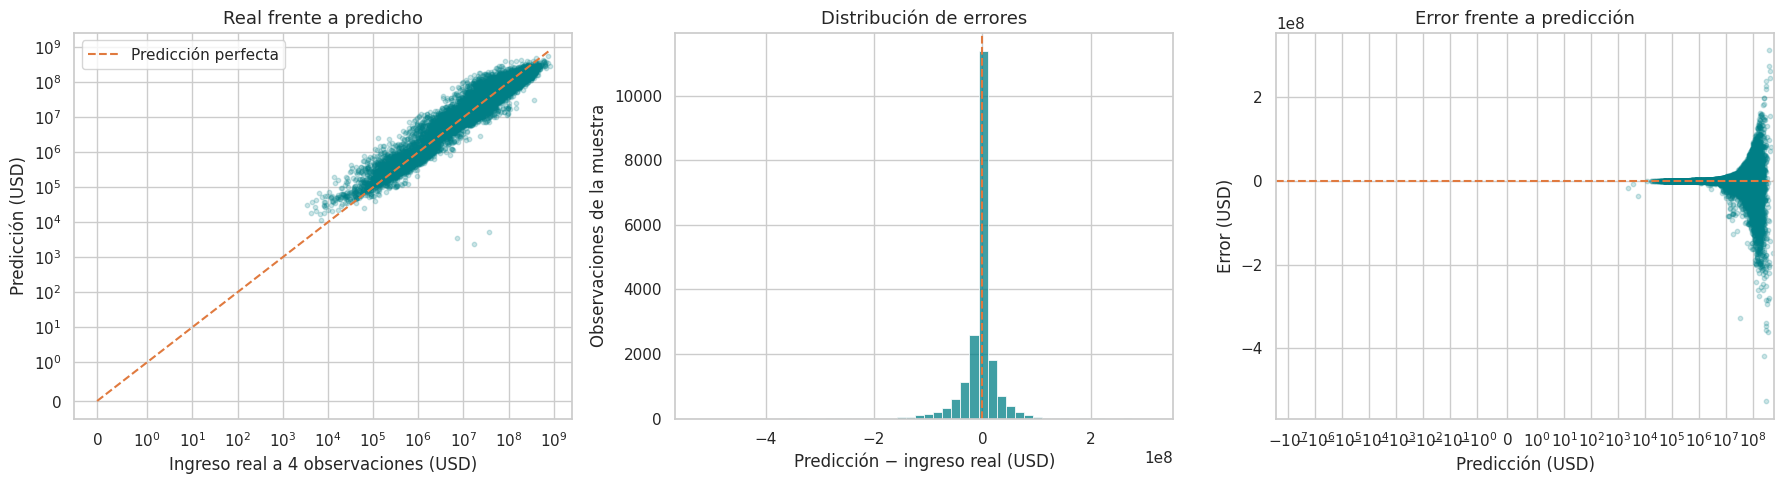

In [ ]:
# Visualizar una muestra acotada de prueba y conservar juntas las tres gráficas de diagnóstico.
plot_predictions_pdf = test_predictions.sample(False, min(1.0, MAX_PLOT_ROWS / N_TEST), SEED).limit(MAX_PLOT_ROWS).toPandas()
print(f"Muestra de diagnóstico: {len(plot_predictions_pdf):,} de {N_TEST:,} registros de prueba.")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(plot_predictions_pdf["label_usd"], plot_predictions_pdf["prediction_usd"], s=10, alpha=0.2, color="#007F86")
upper = max(float(plot_predictions_pdf["label_usd"].max()), float(plot_predictions_pdf["prediction_usd"].max()), 1.0)
axes[0].plot([0, upper], [0, upper], "--", color="#E07A3F", label="Predicción perfecta")
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set(title="Real frente a predicho", xlabel="Ingreso real a 4 observaciones (USD)", ylabel="Predicción (USD)")
axes[0].legend()
sns.histplot(data=plot_predictions_pdf, x="error_usd", bins=50, ax=axes[1], color="#007F86")
axes[1].axvline(0, color="#E07A3F", linestyle="--")
axes[1].set(title="Distribución de errores", xlabel="Predicción − ingreso real (USD)", ylabel="Observaciones de la muestra")
axes[2].scatter(plot_predictions_pdf["prediction_usd"], plot_predictions_pdf["error_usd"], s=10, alpha=0.2, color="#007F86")
axes[2].axhline(0, color="#E07A3F", linestyle="--")
axes[2].set_xscale("symlog", linthresh=1)
axes[2].set(title="Error frente a predicción", xlabel="Predicción (USD)", ylabel="Error (USD)")
plt.tight_layout()
plt.show()

**Diagnóstico de los errores.**

En las **20,000 observaciones** de la muestra, la dispersión real frente a predicho sigue la diagonal de referencia, lo que coincide con la asociación global recogida por el R². Sin embargo, la nube tiene amplitud y presenta casos alejados de la línea, incluidos algunos con ingresos reales de millones y predicciones mucho menores. Las escalas logarítmicas permiten comparar órdenes de magnitud, pero comprimen visualmente las diferencias grandes en dólares.

El histograma concentra la mayor cantidad de errores cerca de cero, con colas hacia ambos lados. La cola negativa se extiende más que la positiva, mostrando subestimaciones extremas de mayor magnitud en esta muestra. La concentración central no implica que el error medio sea cero ni que no haya sesgo: las desviaciones extremas pueden tener mucho peso aunque sean poco frecuentes.

En el panel de error frente a predicción, la dispersión se abre conforme aumenta el ingreso predicho. Los errores en dólares son más amplios en las observaciones de ingresos altos, por lo que su magnitud no se mantiene constante a lo largo de la escala. Este patrón ayuda a interpretar que el RMSE de **33.82 millones** sea considerablemente mayor que el MAE de **16.93 millones**. Las gráficas describen una muestra; las métricas citadas se calcularon con las 546,597 observaciones de prueba.

**Conclusión.**

De los **5,584,706 registros limpios**, **5,470,635 tienen etiqueta**, una cobertura del **97.96%**. Los **114,071 restantes** no cuentan con cuatro observaciones futuras dentro de su serie. La reducción adicional de entrenamiento y validación se debe a las etiquetas que cruzan los cortes temporales, de modo que no debe confundirse la disponibilidad de etiqueta con el número final de filas utilizadas en cada etapa.

La regresión reduce el RMSE frente a persistencia tanto en validación (**15.26%**) como en prueba (**18.87%**). Esto respalda su utilidad para anticipar el ingreso futuro dentro de la simulación evaluada. Aun así, el MAE de **16.93 millones de USD** y la amplitud de los errores en ingresos altos muestran que las predicciones individuales mantienen incertidumbre considerable.

El horizonte tiene una mediana aproximada de **26 días**, una media de **27.96 días** y un rango de **4 a 149 días**. Su cercanía promedio a cuatro semanas no convierte el objetivo en un ingreso a 28 días: se estima el ingreso de la cuarta observación futura, con un intervalo variable, y no la suma de ingresos del período. Como una misma entidad puede aparecer en varios conjuntos temporales, el resultado tampoco mide generalización exclusiva a videojuegos nuevos ni demuestra causalidad.

## 13. CSV para Tableau

Los resultados se organizan en tres archivos independientes en `/content/tableau/`, cada uno con un nivel de detalle distinto:

| Archivo | Contenido y alcance en esta ejecución |
|---|---|
| `mercado_entrenamiento_mensual.csv` | Resumen de los **4,817,424 registros del entrenamiento final**, agrupado por mes, plataforma y género. Incluye sumas y denominadores para obtener promedios ponderados. |
| `predicciones_test_muestra.csv` | **Hasta 20,000 observaciones de prueba** con ingreso real a cuatro observaciones (`ingreso_real_4obs_usd`), fechas, horizonte real (`horizonte_dias`), predicción y error. Permite explorar casos individuales de la muestra. |
| `metricas_test.csv` | RMSE, MAE y R² de regresión y persistencia sobre las **546,597 observaciones de prueba**. Resume la comparación global entre ambos modelos. |

El resumen de mercado describe el entrenamiento final, anterior al 17 de julio de 2024, por lo que no cubre todo el período 2019–2024. Los ingresos proceden del simulador y corresponden a observaciones, no a ventas verificadas ni a ingresos acumulados; la suma de jugadores observados tampoco equivale a usuarios únicos.

Las tres fuentes responden preguntas diferentes: evolución descriptiva del entrenamiento, comportamiento de casos de prueba y desempeño global. Unirlas fila a fila duplicaría o mezclaría valores de distinta granularidad. `README_TABLEAU.md` explica cómo construir el tablero con fuentes independientes y filtros acordes con cada una.

In [ ]:
# Preparar tres tablas con granularidades independientes para Tableau.
market_csv = (final_train.withColumn("mes", F.trunc("obs_date", "month"))
    .groupBy("mes", "platform", "genre").agg(
        F.count("*").alias("observaciones"),
        F.sum("estimated_revenue_usd").alias("ingresos_observados_usd"),
        F.sum("current_price_usd").alias("precio_total_usd"),
        F.count("current_price_usd").alias("observaciones_precio"),
        F.sum("discount_pct").alias("descuento_total_pct"),
        F.count("discount_pct").alias("observaciones_descuento"),
        F.sum("concurrent_players").alias("jugadores_total"),
        F.count("concurrent_players").alias("observaciones_jugadores"),
        F.sum("steam_rating_pct").alias("valoracion_total_fraccion"),
        F.count("steam_rating_pct").alias("observaciones_valoracion"))
    .withColumnRenamed("platform", "plataforma").withColumnRenamed("genre", "genero")
    .orderBy("mes", "plataforma", "genero"))

sample_csv = (test_predictions.sample(False, min(1.0, MAX_TABLEAU_ROWS / N_TEST), SEED + 1)
    .limit(MAX_TABLEAU_ROWS).select(
        "game_id", F.col("game_name").alias("juego"), F.col("obs_date").alias("fecha_observacion"),
        F.col("target_date").alias("fecha_objetivo"), F.col("horizon_days").alias("horizonte_dias"),
        F.col("platform").alias("plataforma"),
        F.col("storefront").alias("tienda"), F.col("genre").alias("genero"), F.col("publisher_tier").alias("nivel_editora"),
        F.col("current_price_usd").alias("precio_usd"), F.col("discount_pct").alias("descuento_pct"),
        F.col("concurrent_players").alias("jugadores_concurrentes"),
        F.col("estimated_revenue_usd").alias("ingreso_actual_usd"),
        F.col("label_usd").alias("ingreso_real_4obs_usd"), F.col("prediction_usd").alias("prediccion_usd"),
        F.col("estimated_revenue_usd").alias("referencia_usd"), "error_usd",
        F.col("abs_error_usd").alias("error_absoluto_usd")))
metrics_schema = "modelo string, conjunto string, rmse_usd double, mae_usd double, r2 double, registros long"
metrics_csv = spark.createDataFrame([
    (row["modelo"], row["conjunto"], float(row["rmse_usd"]), float(row["mae_usd"]), float(row["r2"]), int(row["registros"]))
    for row in metrics_pdf.to_dict("records")], schema=metrics_schema)

In [ ]:
def export_small_csv(df, filename):
    # coalesce(1) se aplica solo al resumen, la muestra acotada o dos filas de métricas.
    with tempfile.TemporaryDirectory(prefix="tableau_", dir=str(ROOT)) as temporary:
        output = Path(temporary) / "spark_output"
        (df.coalesce(1).write.mode("overwrite").option("header", True)
            .option("encoding", "UTF-8").option("dateFormat", "yyyy-MM-dd").csv(str(output)))
        parts = list(output.glob("part-*.csv"))
        if len(parts) != 1:
            raise RuntimeError(f"Se esperaba un CSV de salida para {filename}.")
        shutil.copyfile(parts[0], TABLEAU_DIR / filename)
    final_path = TABLEAU_DIR / filename
    print(f"{final_path} · {final_path.stat().st_size / 2**20:.2f} MiB")
    return final_path

In [ ]:
# Exportar individualmente el resumen, la muestra y las métricas; se imprimen sus rutas.
csv_paths = [
    export_small_csv(market_csv, "mercado_entrenamiento_mensual.csv"),
    export_small_csv(sample_csv, "predicciones_test_muestra.csv"),
    export_small_csv(metrics_csv, "metricas_test.csv")
]

/content/tableau/mercado_entrenamiento_mensual.csv · 0.86 MiB
/content/tableau/predicciones_test_muestra.csv · 3.83 MiB
/content/tableau/metricas_test.csv · 0.00 MiB


**Archivos exportados.**

La ejecución muestra los tres CSV en `/content/tableau/`: el resumen mensual ocupa **0.86 MiB** y la muestra de predicciones, **3.83 MiB**. El archivo de métricas aparece como **0.00 MiB** por el redondeo de su tamaño a dos decimales; su tabla de origen contiene únicamente las dos filas de resultados, una por modelo, por lo que ese valor no significa que las métricas sean cero.

El resumen permite analizar agregados del entrenamiento final; la muestra, revisar hasta 20,000 casos de prueba; y las métricas, comparar ambos modelos sobre las 546,597 observaciones evaluadas. Esta diferencia de alcance debe mantenerse al construir el tablero: los errores calculados solo con la muestra no sustituyen las métricas completas y las fuentes no deben unirse fila a fila. La guía local describe el montaje y la publicación en Tableau.

### Descargar individualmente desde Colab

Los tres archivos exportados están en `/content/tableau/`. Para descargarlos desde el panel izquierdo, abrir **Archivos → actualizar → tableau** y usar **⋮ → Descargar** en cada CSV. Los botones de la siguiente celda también permiten descargar cada archivo por separado.

La salida muestra un botón para cada entregable, sin crear un ZIP ni iniciar una descarga múltiple automática. Conviene conservar los tres CSV juntos para disponer del resumen, la muestra y las métricas al seguir `README_TABLEAU.md`. Los archivos de `/content/` son temporales y se pierden al eliminar la sesión, por lo que deben descargarse antes de cerrarla.

In [ ]:
buttons = []
for file_path in csv_paths:
    button = widgets.Button(description=f"Descargar {file_path.name}", layout=widgets.Layout(width="430px"))
    button.on_click(lambda _, selected=file_path: files.download(str(selected)))
    buttons.append(button)
display(widgets.VBox(buttons))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Link a tableu: [Tablero publicado](https://public.tableau.com/views/tableu_proyecto/Videojuegos_mercado_e_ingresos_4_observaciones?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

[Imagen del tablero:](https://drive.google.com/file/d/1X2Yd6w50V5wdTGOera-eQWWQZrrZ8Q-T/view?usp=sharing)

![Imagen](https://drive.google.com/uc?export=view&id=1X2Yd6w50V5wdTGOera-eQWWQZrrZ8Q-T)